#SECTION 1 - ASHMI FATHIMA S

##IMPORT LIBRARIES AND PACKAGES

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder,LabelEncoder
from imblearn.over_sampling import SMOTE


##LOAD THE DATASET

In [ ]:
#from google.colab import drive
#drive.mount('/content/drive')

In [ ]:
filepath = "hotel_bookings.csv"
df = pd.read_csv(filepath)

##UNDERSTANDING THE DATA

In [ ]:
df.head(2) #displays first 2 rows

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01


In [ ]:
pd.set_option('display.max_columns', None) #displays all columns

df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [ ]:
df.shape #displays dataset shape

(119390, 32)

In [ ]:
df.info() #dataset information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [ ]:
df.columns #displays column names

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [ ]:
df.dtypes #datatypes of columns

hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults                              int64
children                          float64
babies                              int64
meal                               object
country                            object
market_segment                     object
distribution_channel               object
is_repeated_guest                   int64
previous_cancellations              int64
previous_bookings_not_canceled      int64
reserved_room_type                 object
assigned_room_type                 object
booking_changes                     int64
deposit_type                       object
agent                             

In [ ]:
df.select_dtypes(include='number').columns #displays numerical cols

Index(['is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_week_number', 'arrival_date_day_of_month',
       'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children',
       'babies', 'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company',
       'days_in_waiting_list', 'adr', 'required_car_parking_spaces',
       'total_of_special_requests'],
      dtype='object')

In [ ]:
df.select_dtypes(include=['object', 'string']).columns #displays cat cols

Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'assigned_room_type',
       'deposit_type', 'customer_type', 'reservation_status',
       'reservation_status_date'],
      dtype='object')

In [ ]:
df.describe() #summary

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


In [ ]:
df['reservation_status_date'] = pd.to_datetime(
    df['reservation_status_date']
)

#converting from object to datetime

In [ ]:
df.dtypes

hotel                                     object
is_canceled                                int64
lead_time                                  int64
arrival_date_year                          int64
arrival_date_month                        object
arrival_date_week_number                   int64
arrival_date_day_of_month                  int64
stays_in_weekend_nights                    int64
stays_in_week_nights                       int64
adults                                     int64
children                                 float64
babies                                     int64
meal                                      object
country                                   object
market_segment                            object
distribution_channel                      object
is_repeated_guest                          int64
previous_cancellations                     int64
previous_bookings_not_canceled             int64
reserved_room_type                        object
assigned_room_type  

##MISSING VALUES HANDLING

In [ ]:
missing = df.isna().sum()
print(missing) #checking missing values

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [ ]:
missing_percent = (df.isnull().sum() / len(df)) * 100
print(missing_percent) #Missing value %

hotel                              0.000000
is_canceled                        0.000000
lead_time                          0.000000
arrival_date_year                  0.000000
arrival_date_month                 0.000000
arrival_date_week_number           0.000000
arrival_date_day_of_month          0.000000
stays_in_weekend_nights            0.000000
stays_in_week_nights               0.000000
adults                             0.000000
children                           0.003350
babies                             0.000000
meal                               0.000000
country                            0.408744
market_segment                     0.000000
distribution_channel               0.000000
is_repeated_guest                  0.000000
previous_cancellations             0.000000
previous_bookings_not_canceled     0.000000
reserved_room_type                 0.000000
assigned_room_type                 0.000000
booking_changes                    0.000000
deposit_type                    

In [ ]:
print(missing[missing > 0]) #displaying only missing value cols

children         4
country        488
agent        16340
company     112593
dtype: int64


##DUPLICATE VALUE HANDLING

In [ ]:
df.duplicated().sum() #checking duplicates

31994

In [ ]:
df.drop_duplicates(inplace=True) #deleting duplicates

In [ ]:
df.duplicated().sum()

0

In [ ]:
df.shape

(87396, 32)

##EDA

##UNIVARIATE ANALYSIS

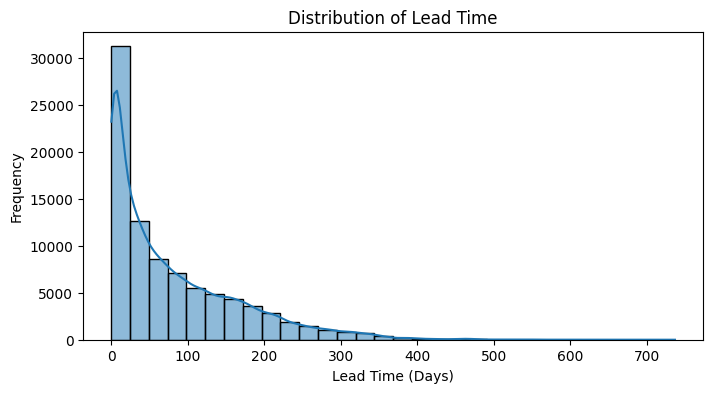

In [ ]:
plt.figure(figsize=(8, 4))

sns.histplot(data=df, x='lead_time', bins=30, kde=True)

plt.title('Distribution of Lead Time')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Frequency')

plt.show() #num analysis

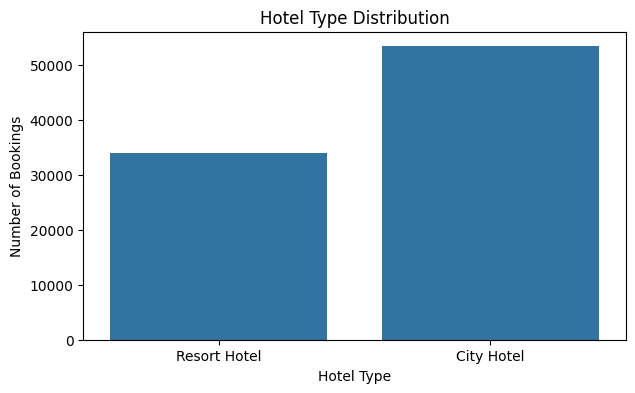

In [ ]:
plt.figure(figsize=(7, 4))

sns.countplot(data=df, x='hotel')

plt.title('Hotel Type Distribution')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')

plt.show() #cat analysis

##BIVARIATE ANALYSIS

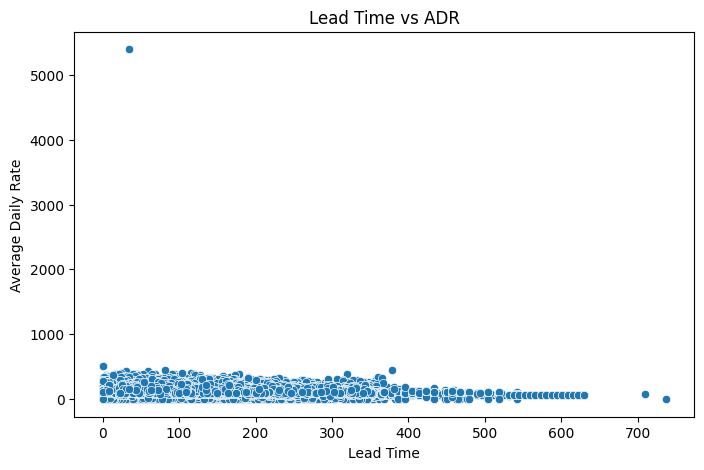

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df,x='lead_time',y='adr')

plt.title('Lead Time vs ADR')
plt.xlabel('Lead Time')
plt.ylabel('Average Daily Rate')

plt.show() #num vs num analysis

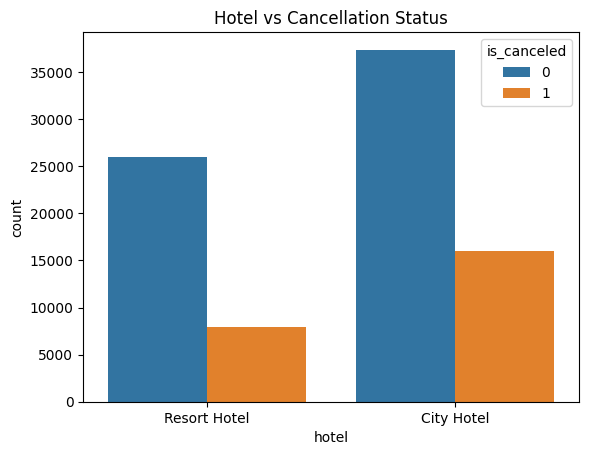

In [ ]:
sns.countplot(data=df,x='hotel',hue='is_canceled')

plt.title('Hotel vs Cancellation Status')
plt.show() #cat vs cat analysis

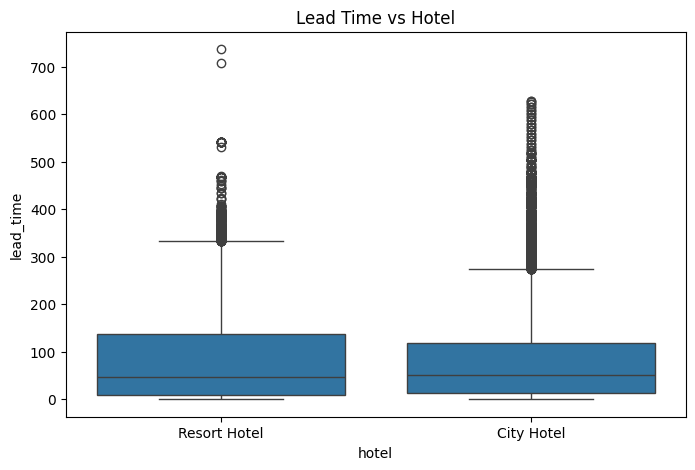

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df,x='hotel',y='lead_time')

plt.title('Lead Time vs Hotel')

plt.show() #num vs cat analysis

##DATA VISUALIZATION

In [ ]:
num_cols = df.select_dtypes(include='number').columns

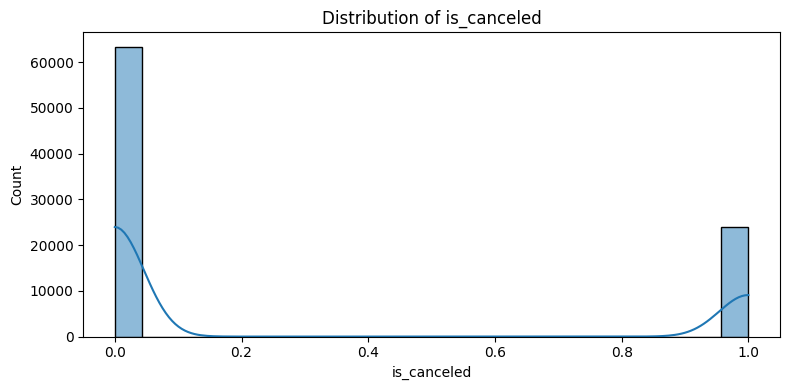

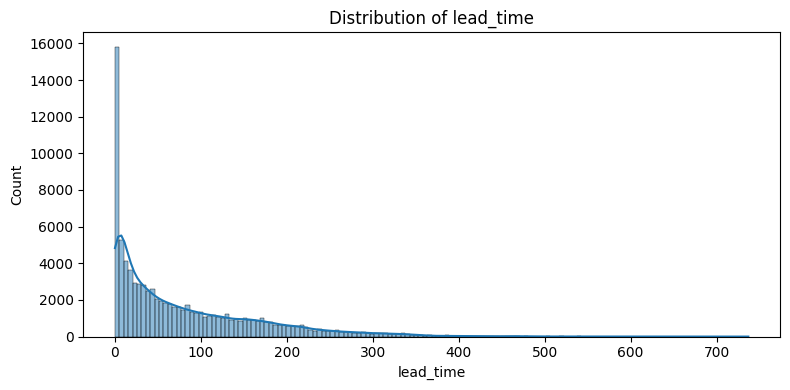

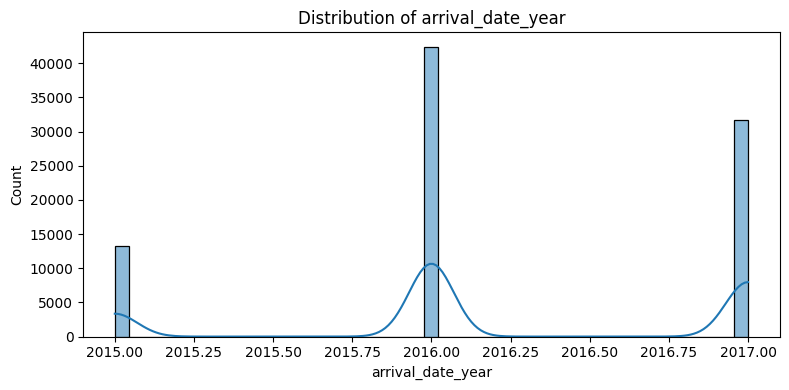

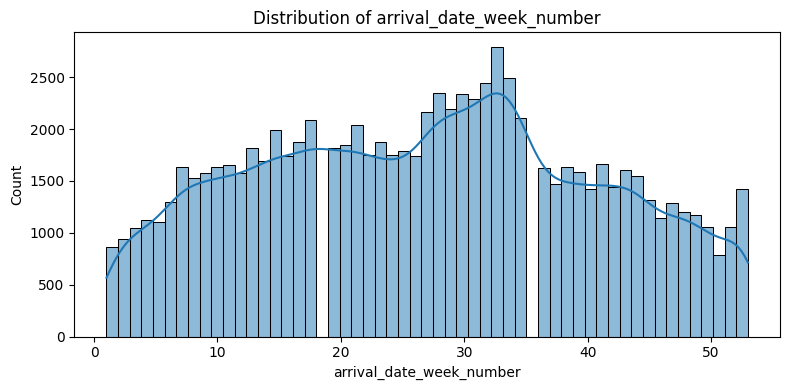

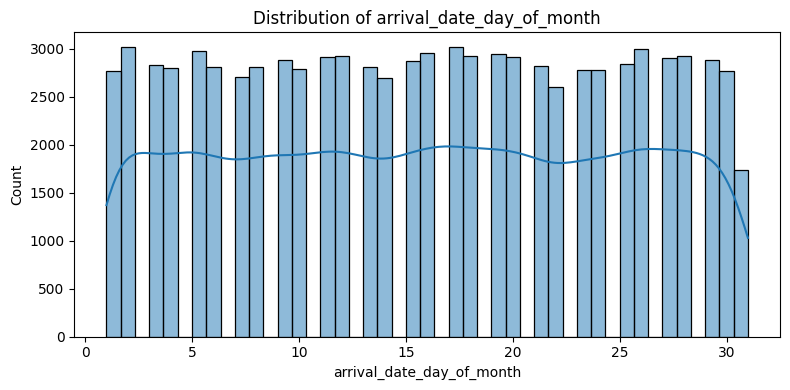

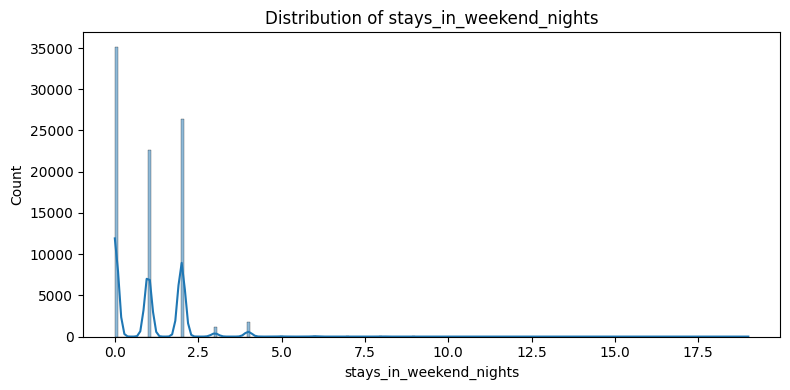

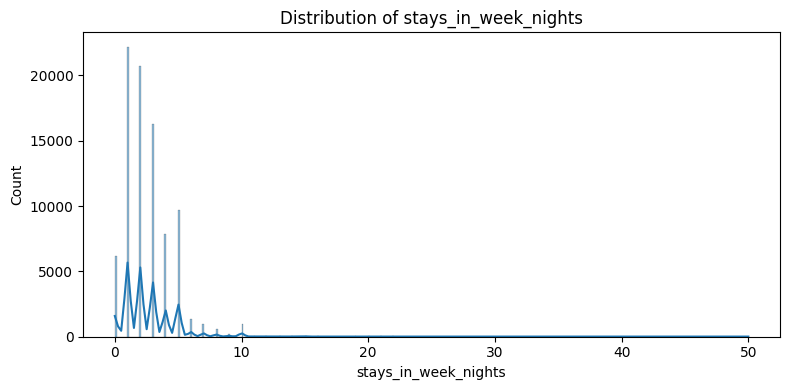

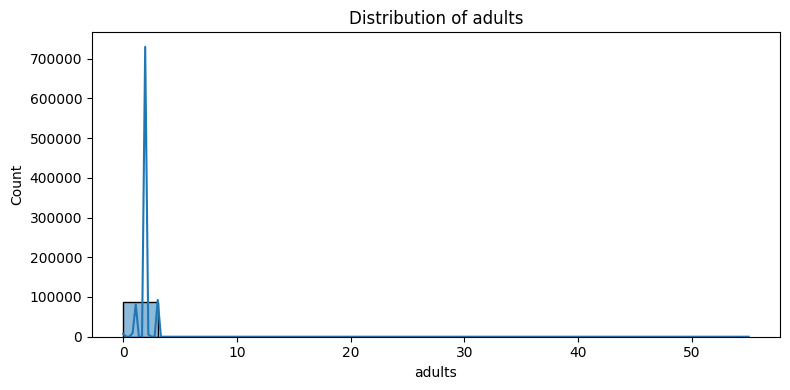

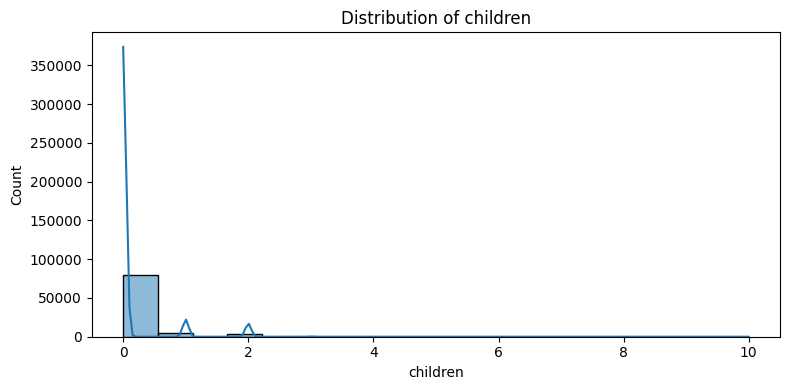

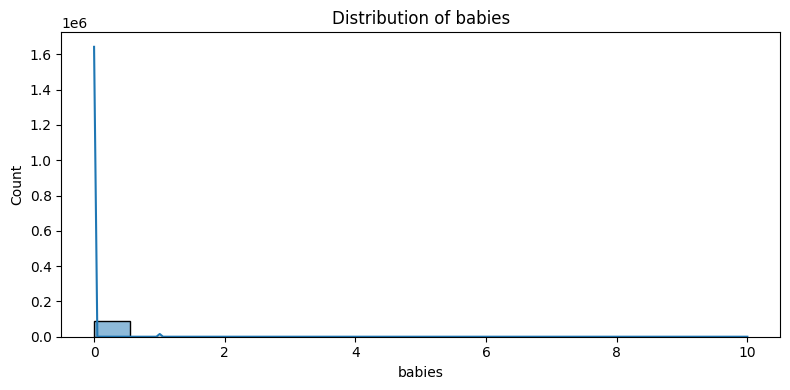

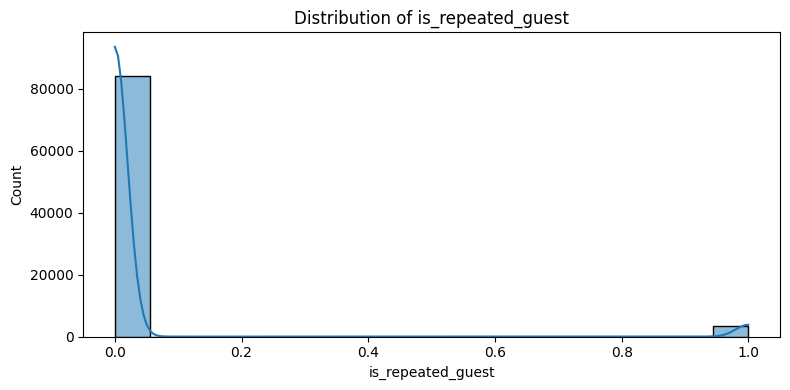

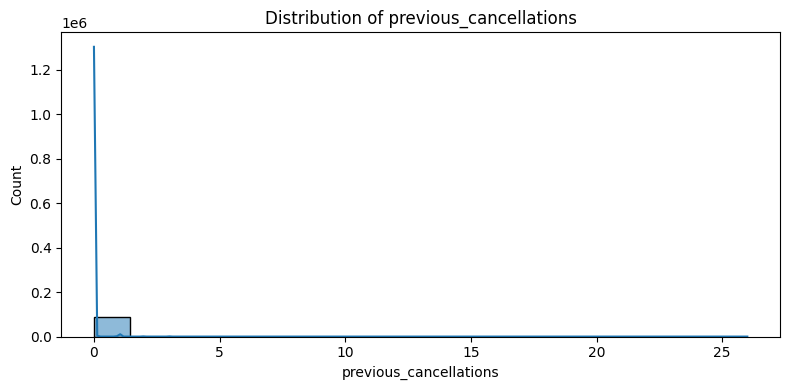

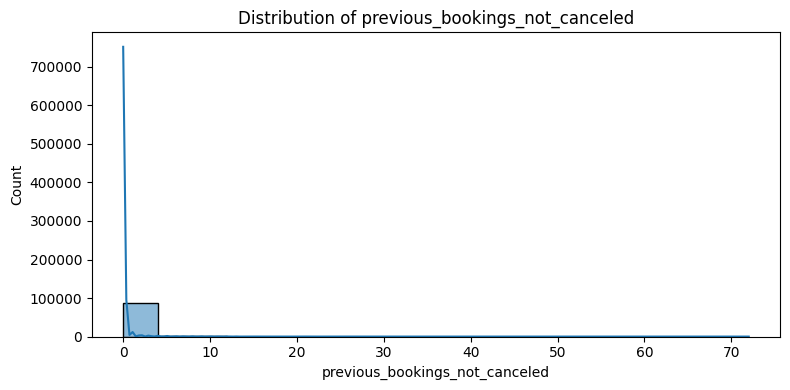

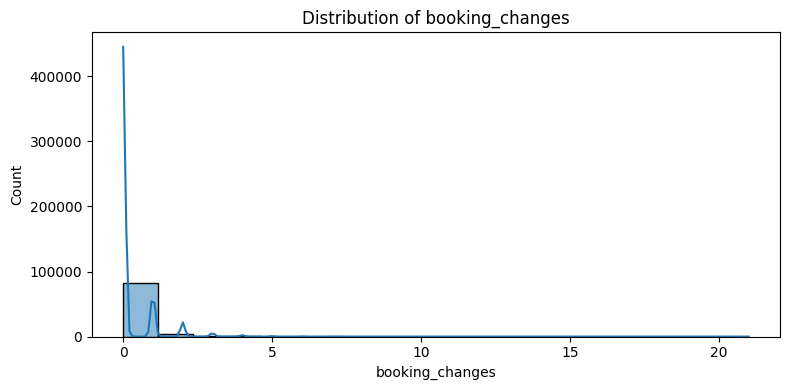

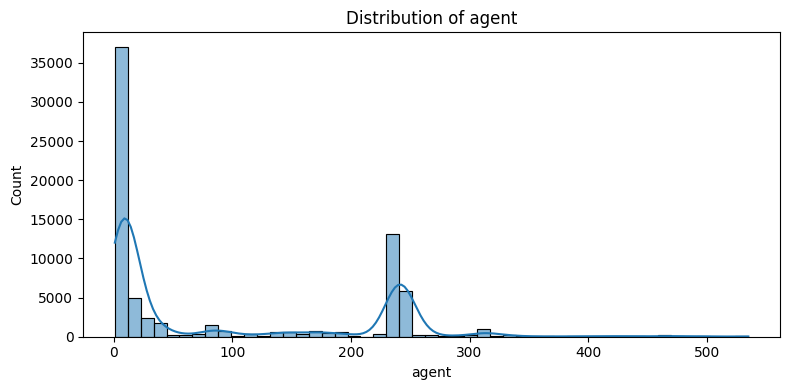

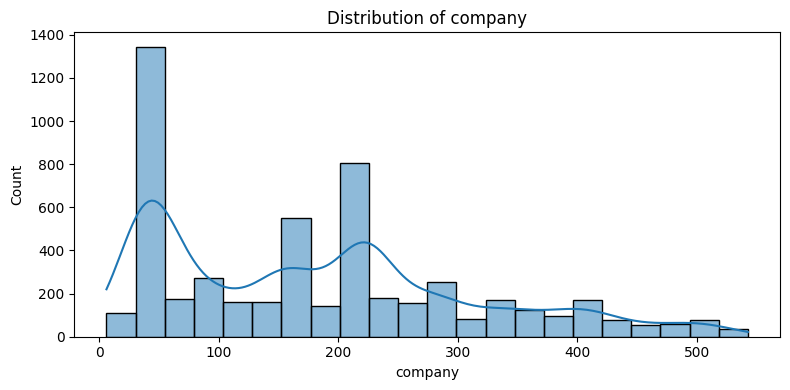

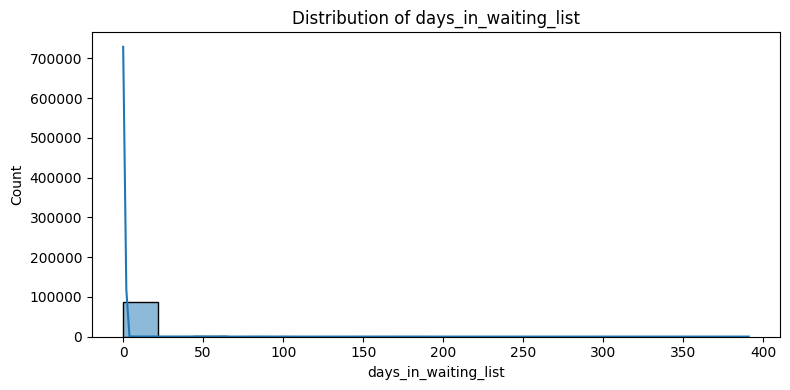

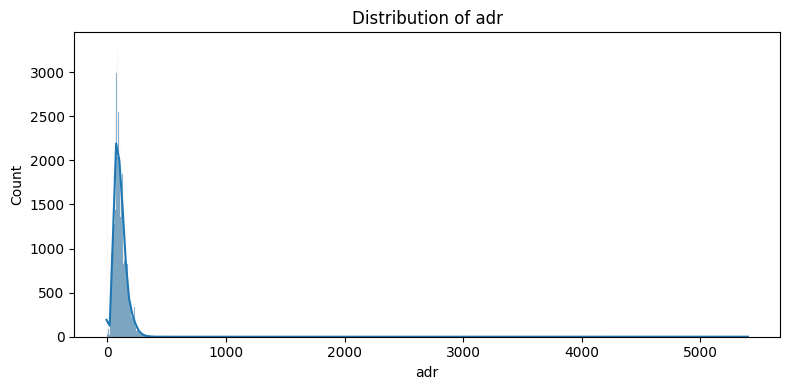

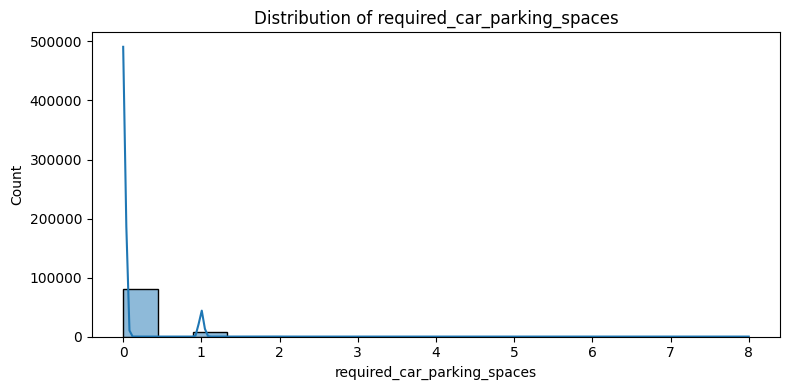

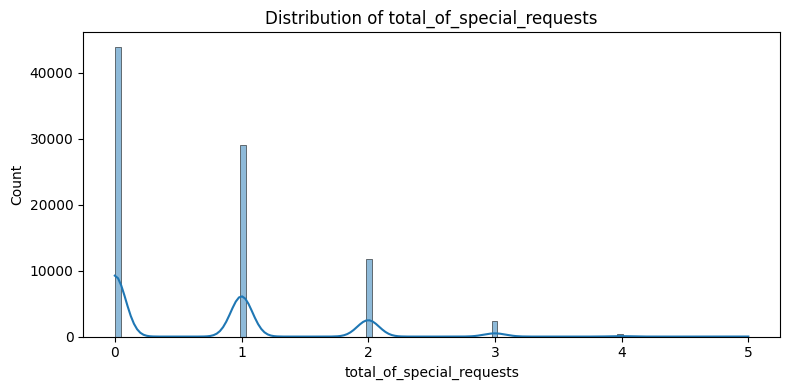

In [ ]:
for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
    plt.tight_layout()
    plt.show()

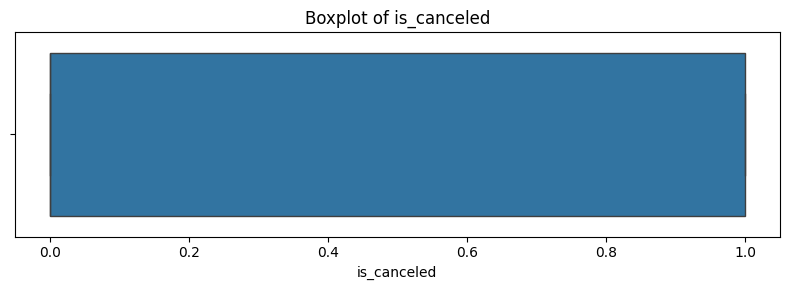

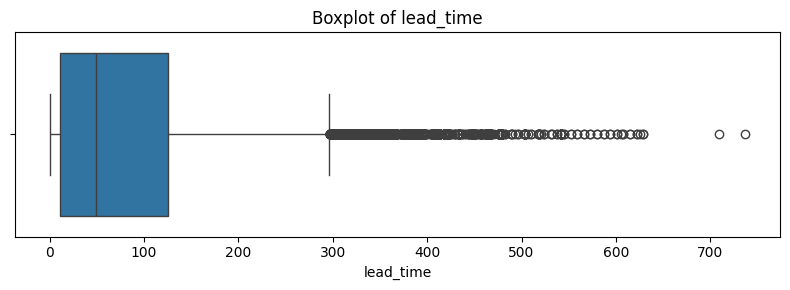

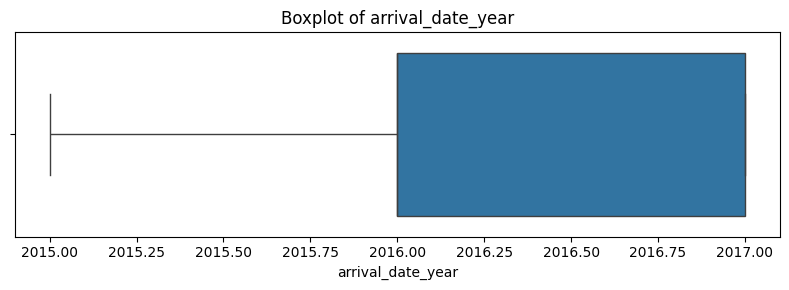

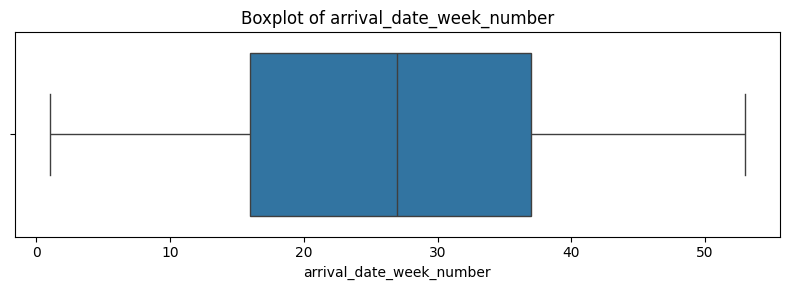

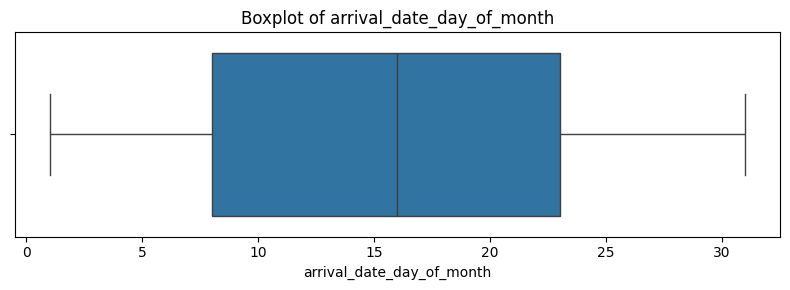

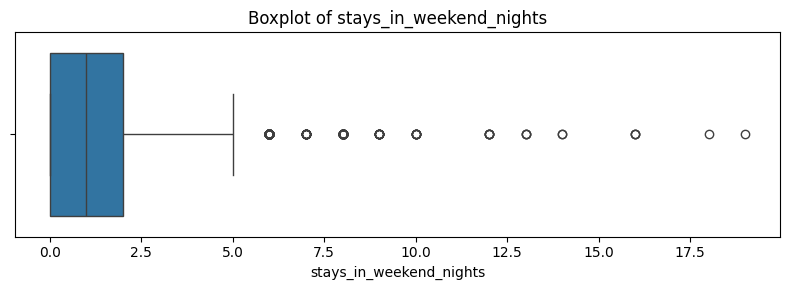

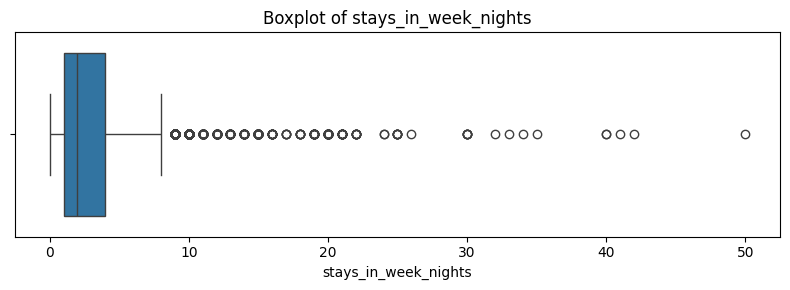

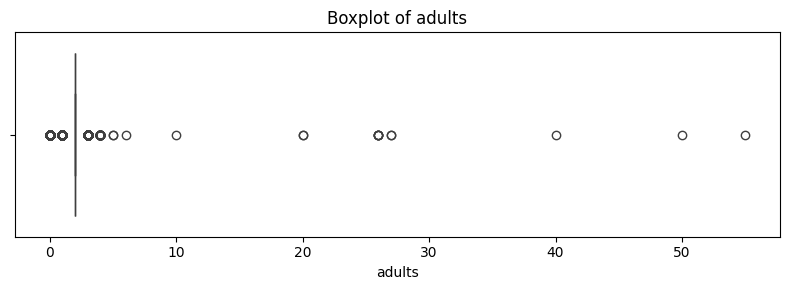

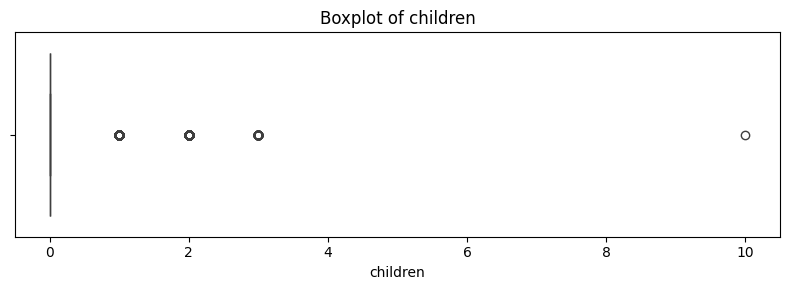

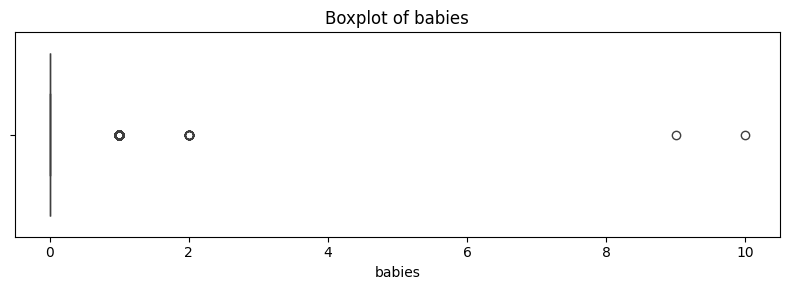

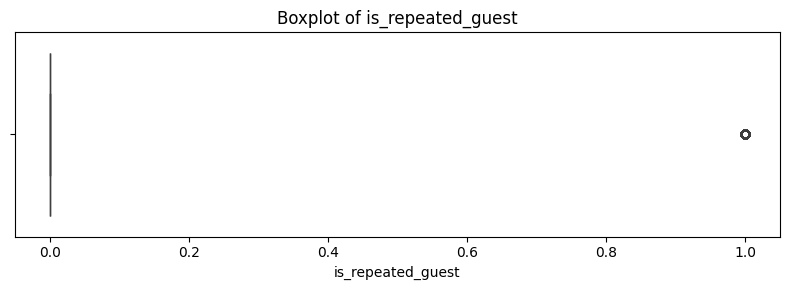

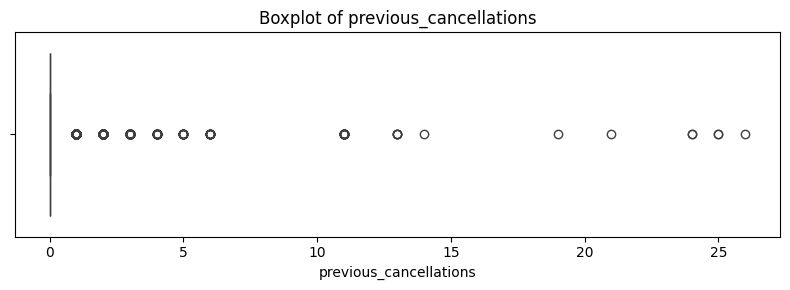

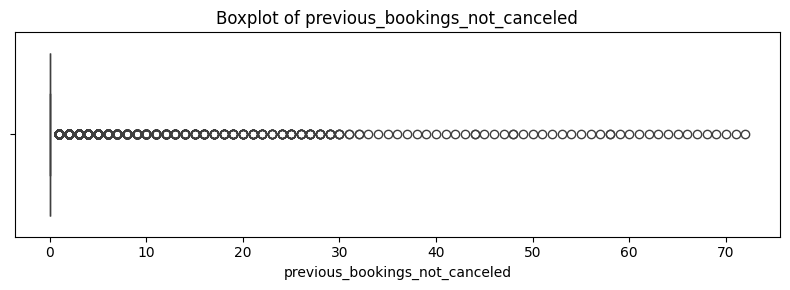

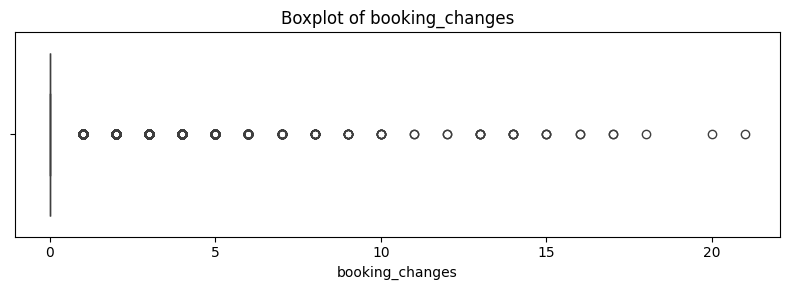

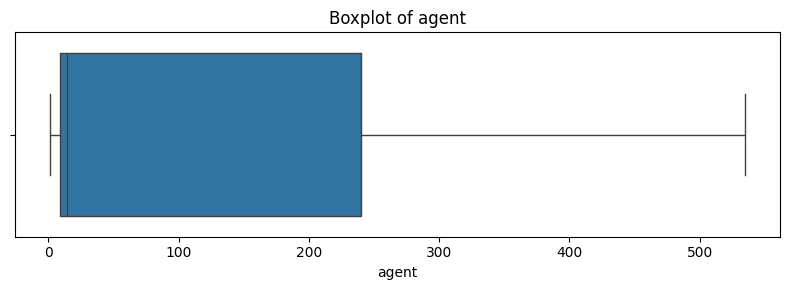

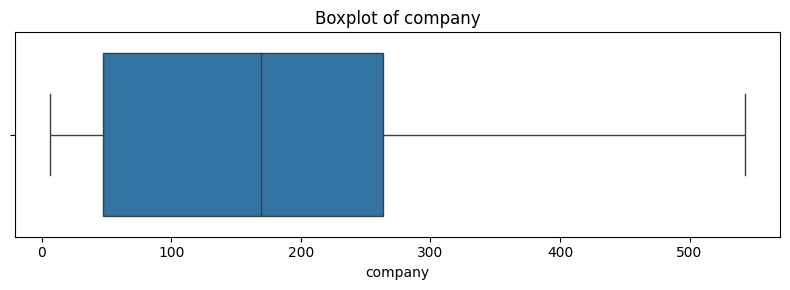

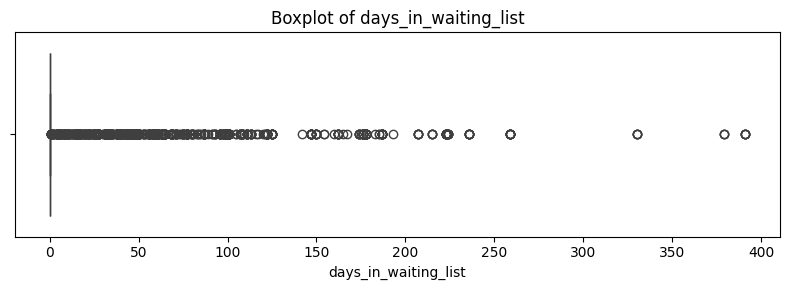

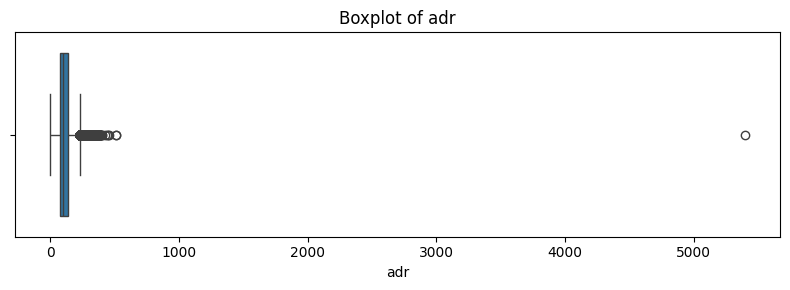

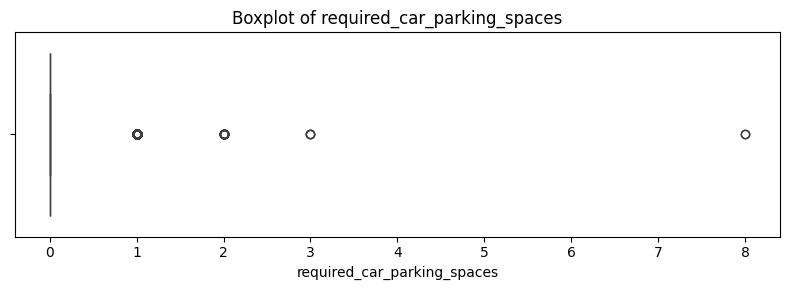

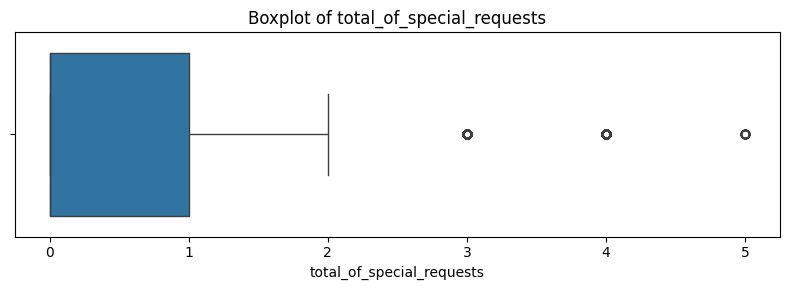

In [ ]:
for col in num_cols:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.tight_layout()
    plt.show()

In [ ]:
cat_cols = df.select_dtypes(include=['object', 'string']).columns

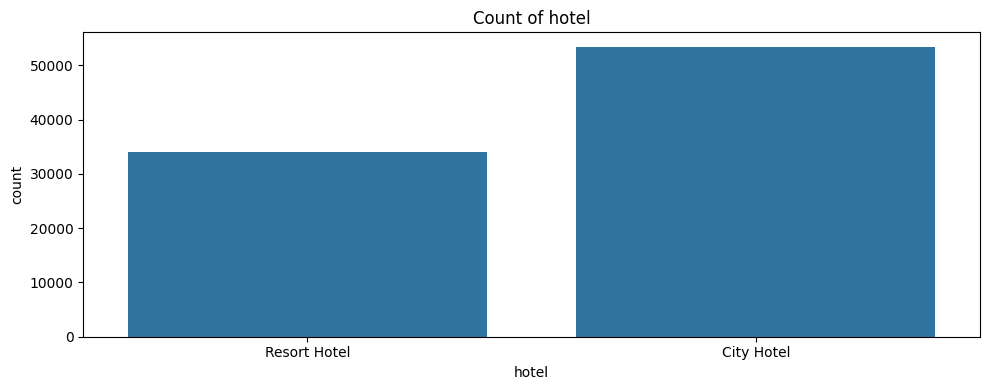

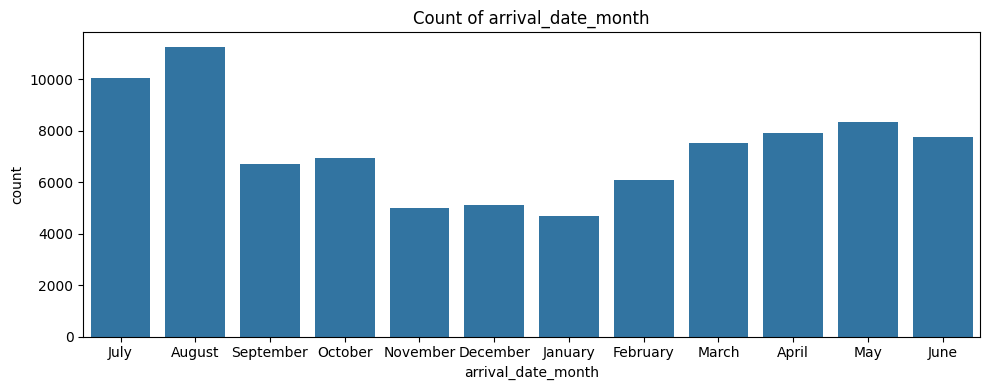

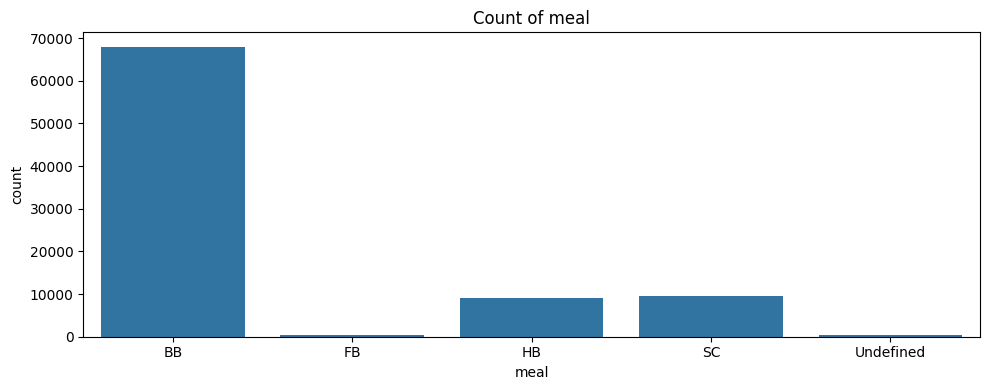

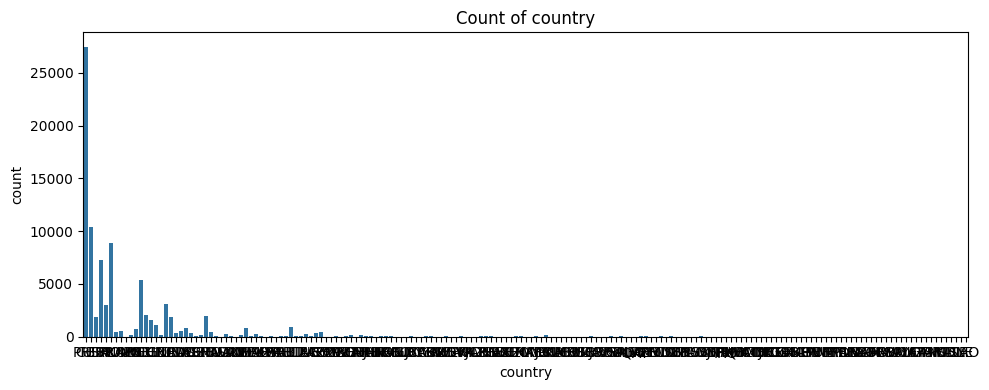

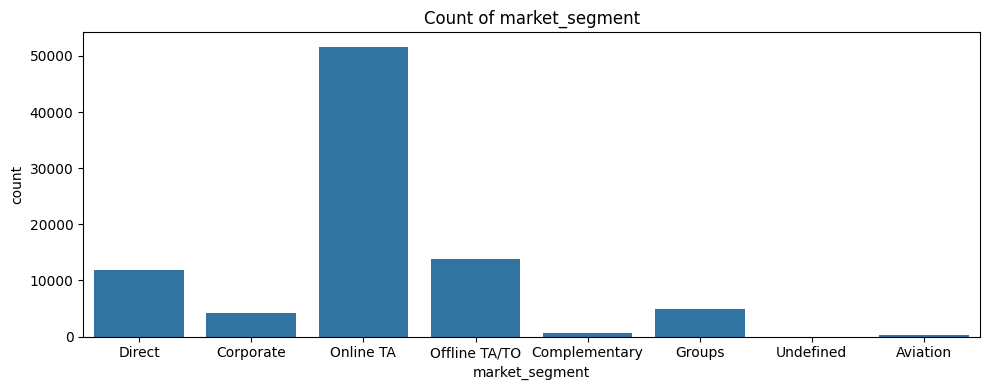

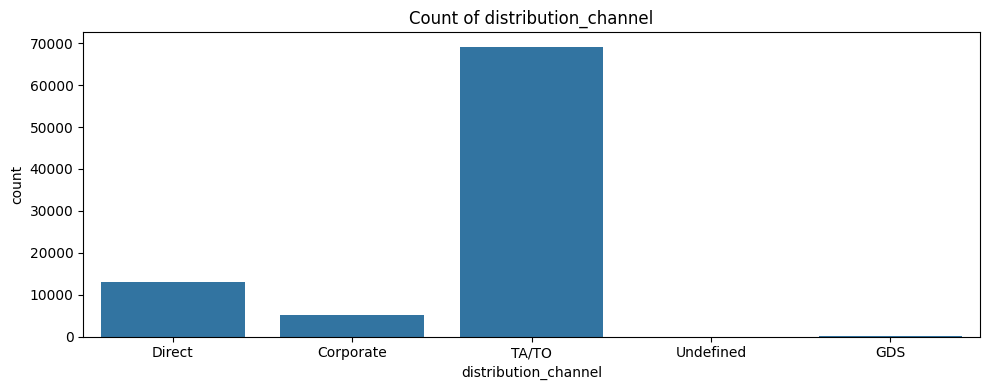

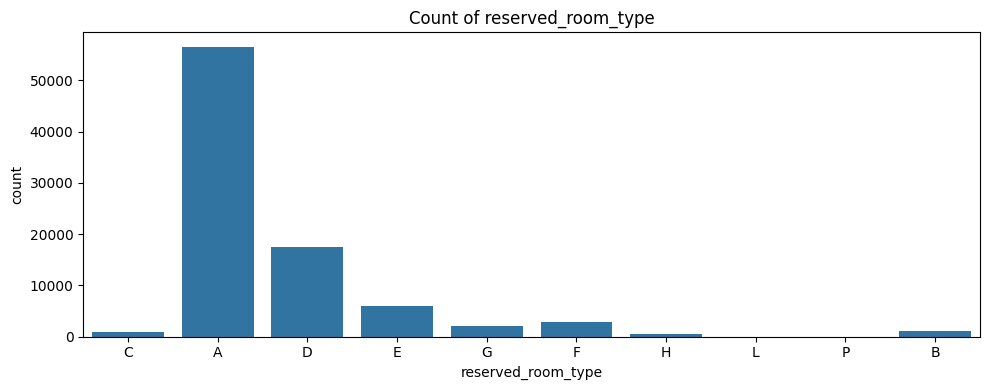

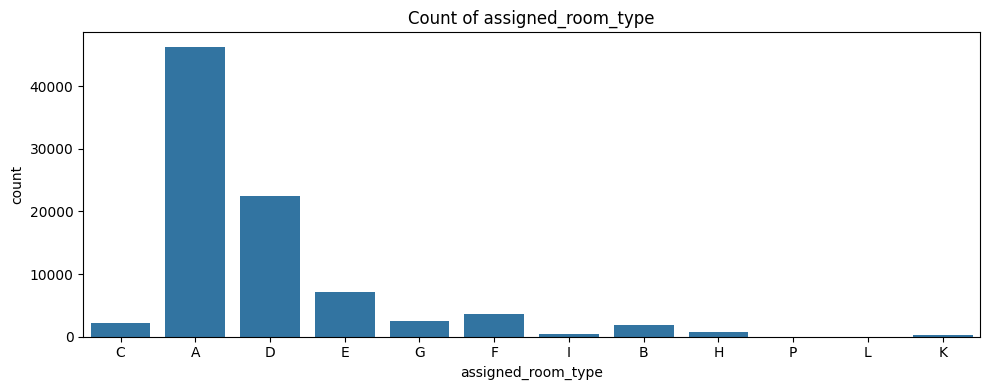

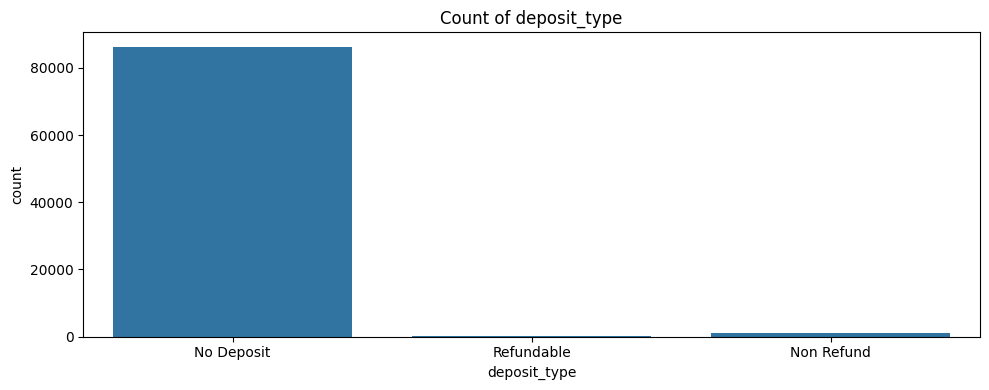

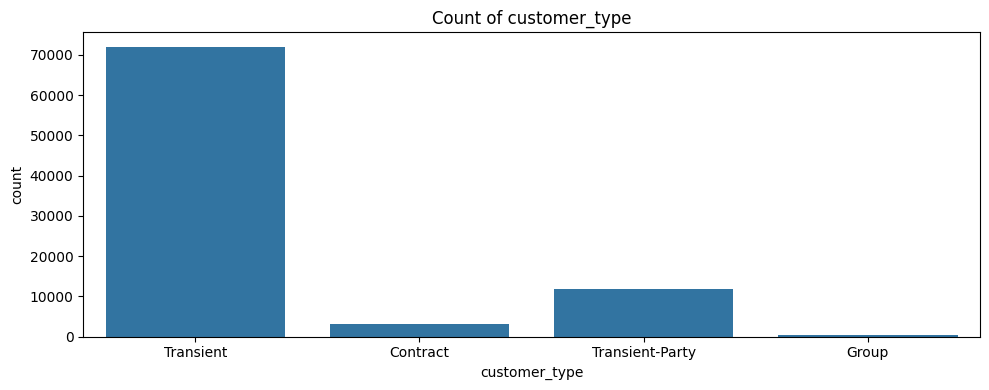

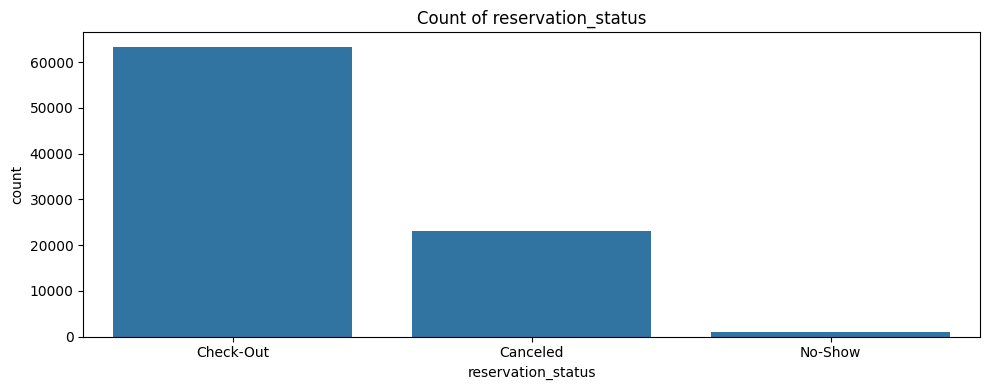

In [ ]:
for col in cat_cols:
    plt.figure(figsize=(10, 4))
    sns.countplot(data=df, x=col)
    plt.title(f'Count of {col}')
    plt.tight_layout()
    plt.show()

##TARGET VARIABLE IDENTIFICATION

In [ ]:
target = 'is_canceled'

print("Target Variable:", target)

Target Variable: is_canceled


In [ ]:
df['is_canceled'].unique()

array([0, 1], dtype=int64)

In [ ]:
df['is_canceled'].value_counts() #checking values

is_canceled
0    63371
1    24025
Name: count, dtype: int64

#SECTION 2 - GOKUL R.S

## SEPARATE FEATURES (X) AND TARGET (y)

In [ ]:
# Drop unnecessary and target leakage columns

df = df.drop(
    columns=[
        'agent',
        'company'
    ],
    errors='ignore'
)
#company has 94% missing, agent is an ID column so we dropped the column.
#children has 4 missing, hence removing those rows.
df=df.dropna(subset=["children"])
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])
df['status_year']  = df['reservation_status_date'].dt.year
df['status_month'] = df['reservation_status_date'].dt.month
df['status_day']   = df['reservation_status_date'].dt.day
df = df.drop(columns=['reservation_status_date'])

print("Remaining columns:")
print(df.columns.tolist())

Remaining columns:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'status_year', 'status_month', 'status_day']


In [ ]:
# reservation_status and reservation_status_date are only known AFTER the booking
# is cancelled or completed, so they leak the answer -> removed from the features
y = df[target]
X = df.drop(columns=[target])

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (87392, 31)
y shape: (87392,)


## TRAIN-TEST SPLIT

In [ ]:
# 80% train, 20% test. stratify keeps the same cancel ratio in both parts,
# random_state makes the split repeatable

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (69913, 31) | X_test: (17479, 31)
y_train: (69913,) | y_test: (17479,)


## SEPARATE NUMERICAL AND CATEGORICAL FEATURES

In [ ]:
numerical_cols = X_train.select_dtypes(include='number').columns.tolist()
categorical_cols = X_train.select_dtypes(exclude='number').columns.tolist()

print("Numerical features (", len(numerical_cols), "):", numerical_cols)
print("\nCategorical features (", len(categorical_cols), "):", categorical_cols)

Numerical features ( 20 ): ['lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'status_year', 'status_month', 'status_day']

Categorical features ( 11 ): ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status']


#SECTION 3 - HARISANKER S PALERI

## NUMERICAL FEATURE PREPROCESSING

In [ ]:
X_train_num = X_train[numerical_cols].astype(float)
X_test_num = X_test[numerical_cols].astype(float)

print("Missing values in numerical train data:")
print(X_train_num.isnull().sum()[X_train_num.isnull().sum() > 0])

Missing values in numerical train data:
Series([], dtype: int64)


## MISSING VALUE IMPUTATION (NUMERICAL)

In [ ]:
# Numerical: median, learned from TRAIN only and applied to both train and test
num_imputer = SimpleImputer(strategy='median')
X_train_num_imp = pd.DataFrame(
    num_imputer.fit_transform(X_train_num),
    columns=numerical_cols, index=X_train_num.index
)
X_test_num_imp = pd.DataFrame(
    num_imputer.transform(X_test_num),
    columns=numerical_cols, index=X_test_num.index
)

# Categorical: fill missing values (only 'country') with 'Unknown'
cat_imputer = SimpleImputer(strategy='constant', fill_value='Unknown')
X_train_cat = pd.DataFrame(
    cat_imputer.fit_transform(X_train[categorical_cols]),
    columns=categorical_cols, index=X_train.index
)
X_test_cat = pd.DataFrame(
    cat_imputer.transform(X_test[categorical_cols]),
    columns=categorical_cols, index=X_test.index
)

print("Missing after imputation (numerical):",
      int(X_train_num_imp.isnull().sum().sum()), "/", int(X_test_num_imp.isnull().sum().sum()))
print("Missing after imputation (categorical):",
      int(X_train_cat.isnull().sum().sum()), "/", int(X_test_cat.isnull().sum().sum()))

# Next steps use: X_train_num_imp, X_test_num_imp  (numerical)
#                 X_train_cat, X_test_cat          (categorical)
#                 y_train, y_test                  (target)

Missing after imputation (numerical): 0 / 0
Missing after imputation (categorical): 0 / 0


In [ ]:
X_train_cat.head()

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status
77305,City Hotel,September,BB,PRT,Direct,Direct,A,E,No Deposit,Transient,Check-Out
114516,City Hotel,June,SC,GBR,Online TA,TA/TO,A,A,No Deposit,Transient-Party,Check-Out
103149,City Hotel,December,BB,ITA,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out
22519,Resort Hotel,March,BB,PRT,Online TA,TA/TO,A,C,No Deposit,Transient,Check-Out
514,Resort Hotel,July,BB,PRT,Direct,Direct,E,E,No Deposit,Transient,Check-Out


# OUTLIER HANDLING

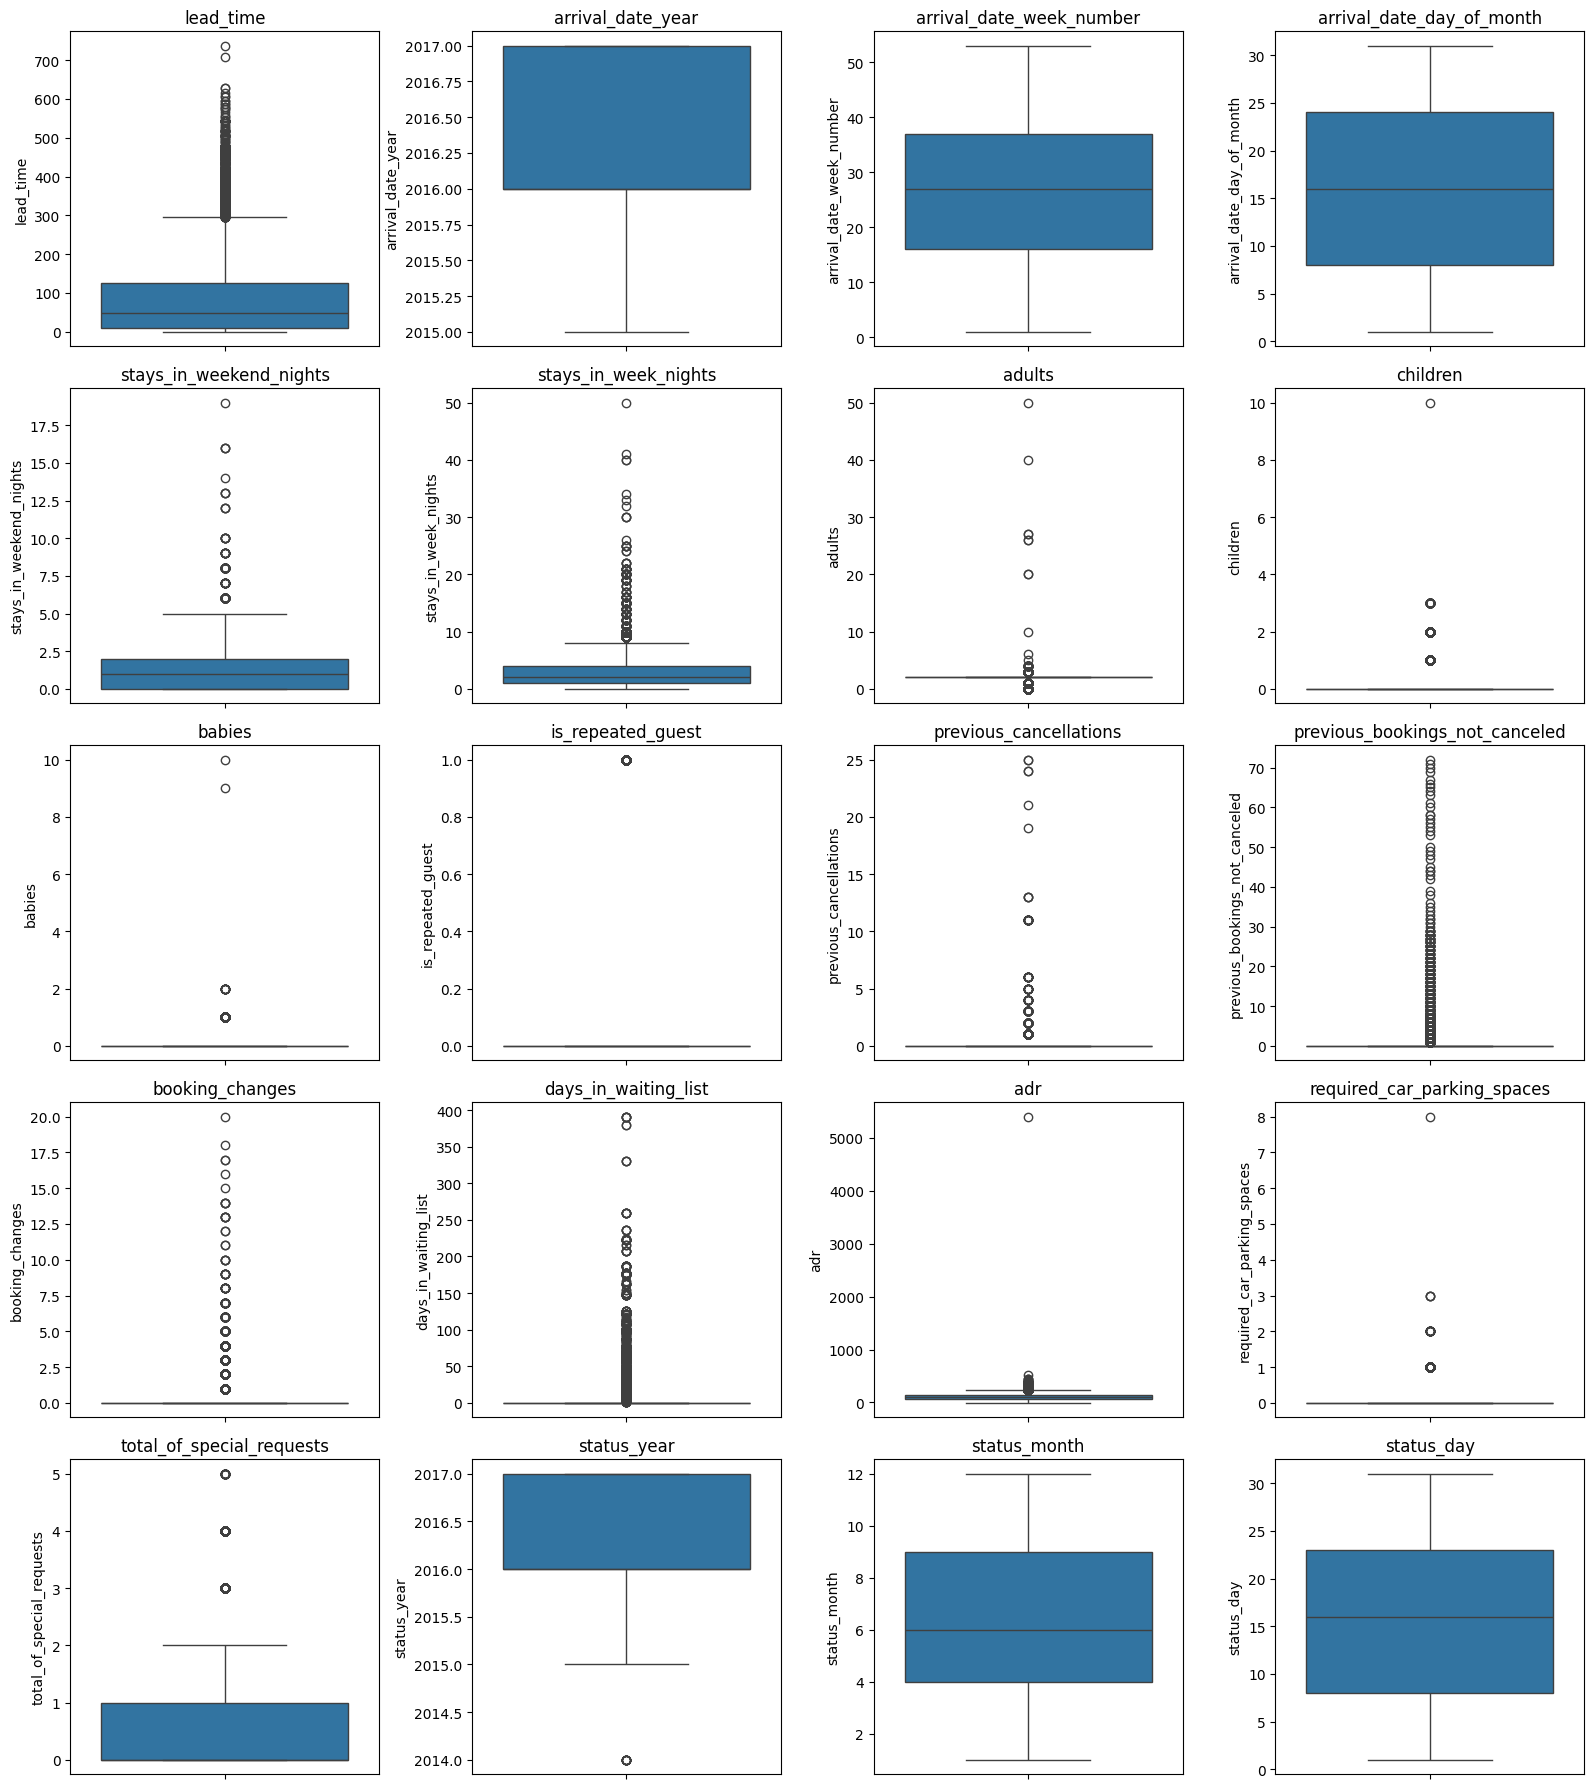

In [ ]:
# checking for outliers using boxplots

plt.figure(figsize=(16, 18))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(5, 4, i)
    sns.boxplot(X_train_num_imp[col])
    plt.title(col)
plt.tight_layout()
plt.show()

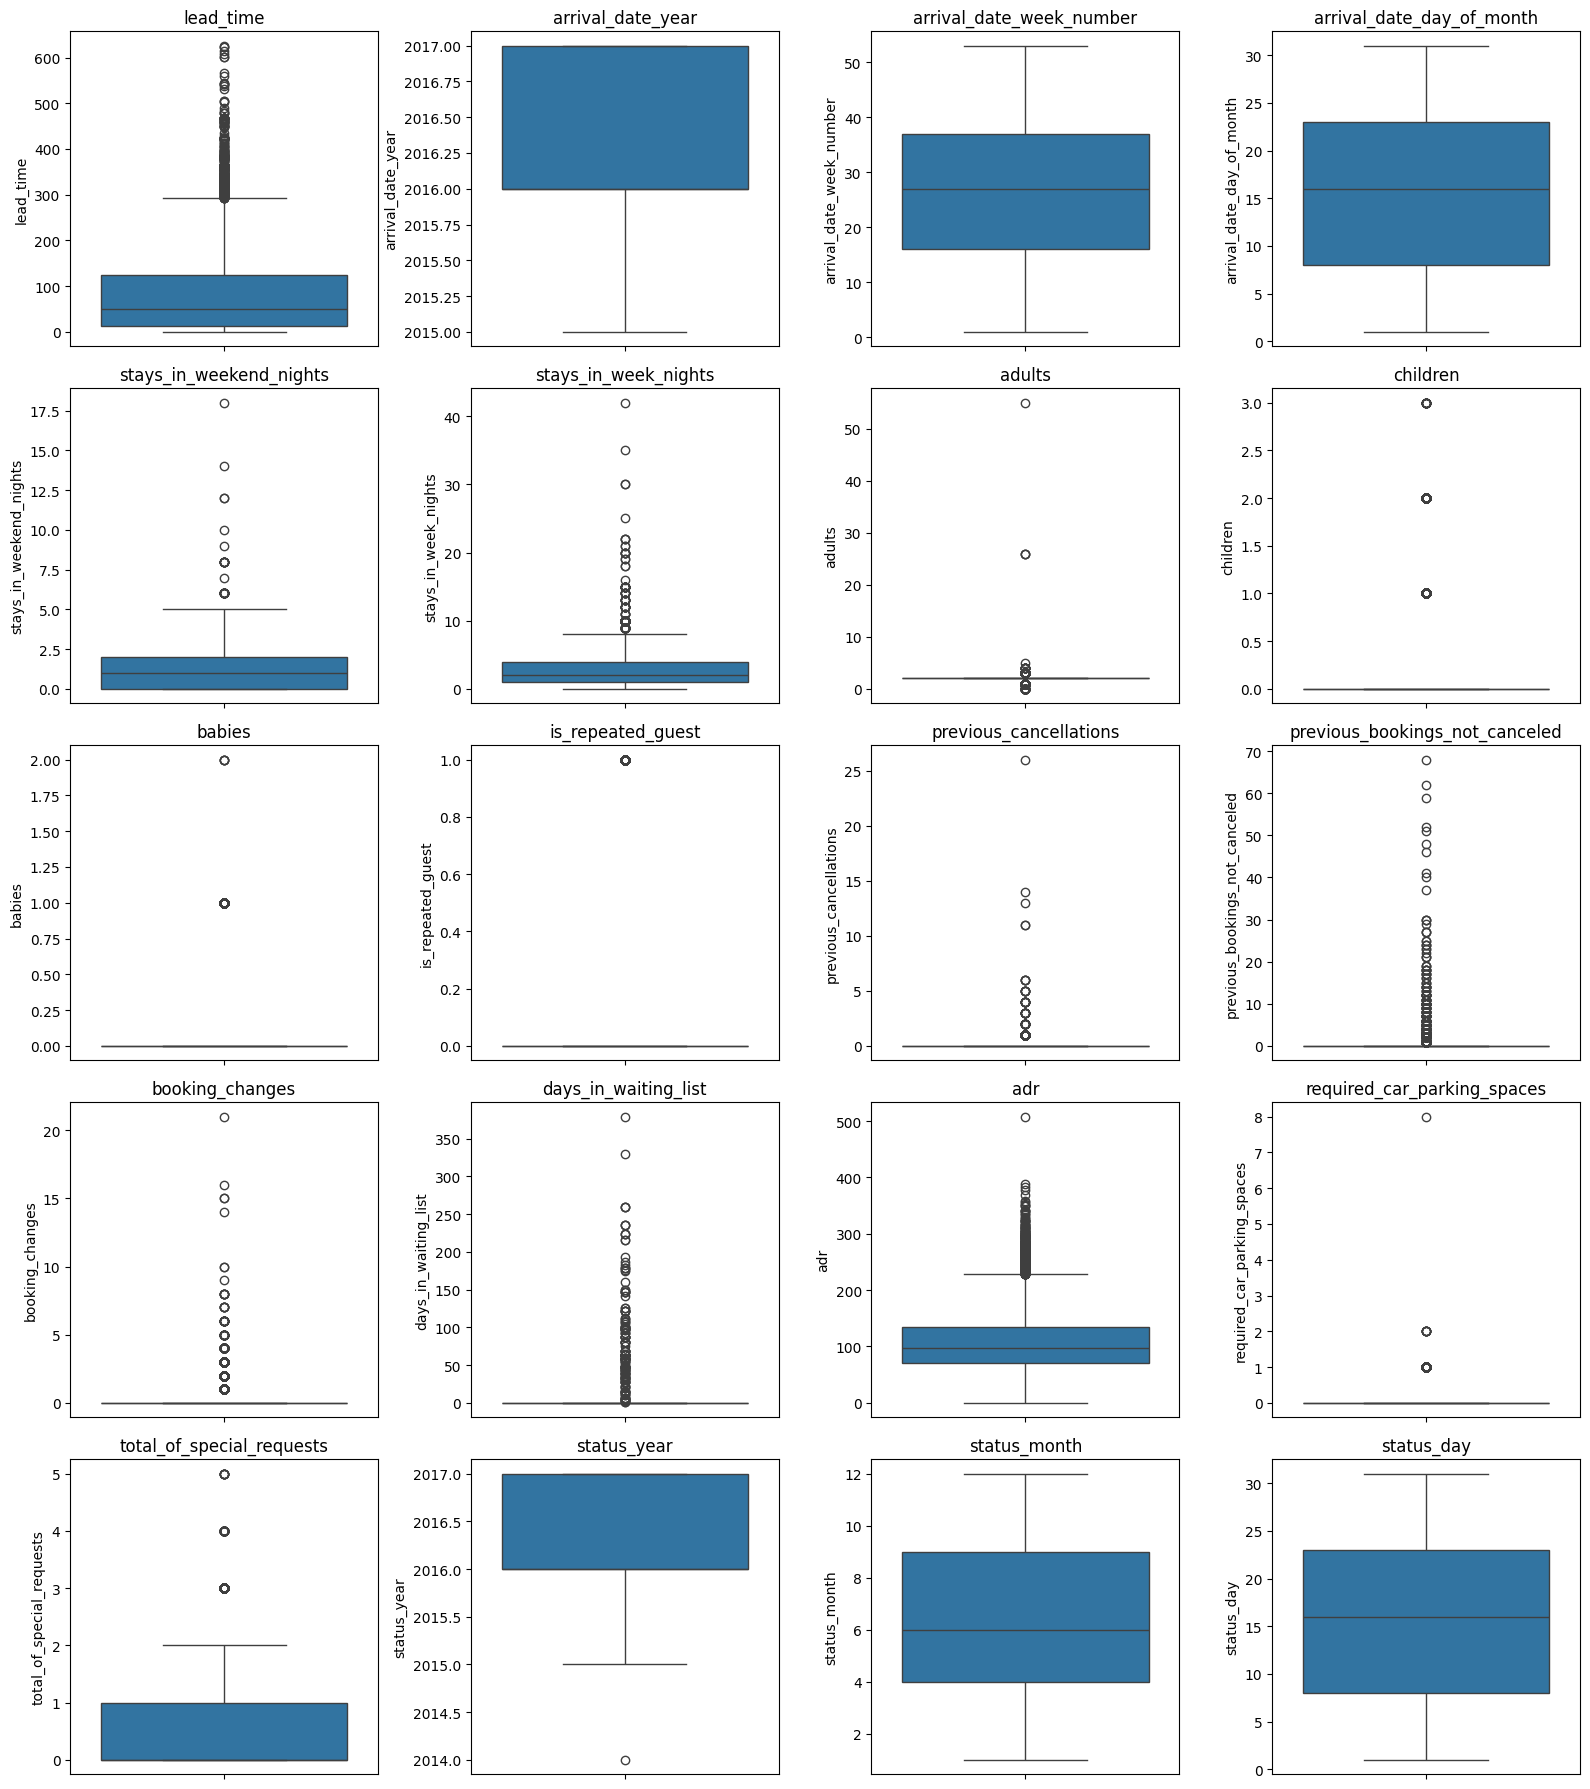

In [ ]:
plt.figure(figsize=(16, 18))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(5, 4, i)
    sns.boxplot(X_test_num_imp[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [ ]:
# Clipping every numerical column using the IQR limits calculated from TRAIN only.
# The same TRAIN limits are applied to both train and test (no data leakage).

for col in numerical_cols:
    Q1 = X_train_num_imp[col].quantile(0.25)
    Q3 = X_train_num_imp[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    X_train_num_imp[col] = X_train_num_imp[col].clip(lower, upper)
    X_test_num_imp[col] = X_test_num_imp[col].clip(lower, upper)

X_train_num_imp.head(3)

,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,status_year,status_month,status_day
77305,4.0,2015.0,38.0,15.0,0.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,95.00,0.0,1.0,2015.0,9.0,17.0
114516,97.0,2017.0,25.0,18.0,2.0,3.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,126.00,0.0,0.0,2017.0,6.0,23.0
103149,22.0,2016.0,50.0,8.0,2.0,3.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,90.78,0.0,1.0,2016.0,12.0,13.0


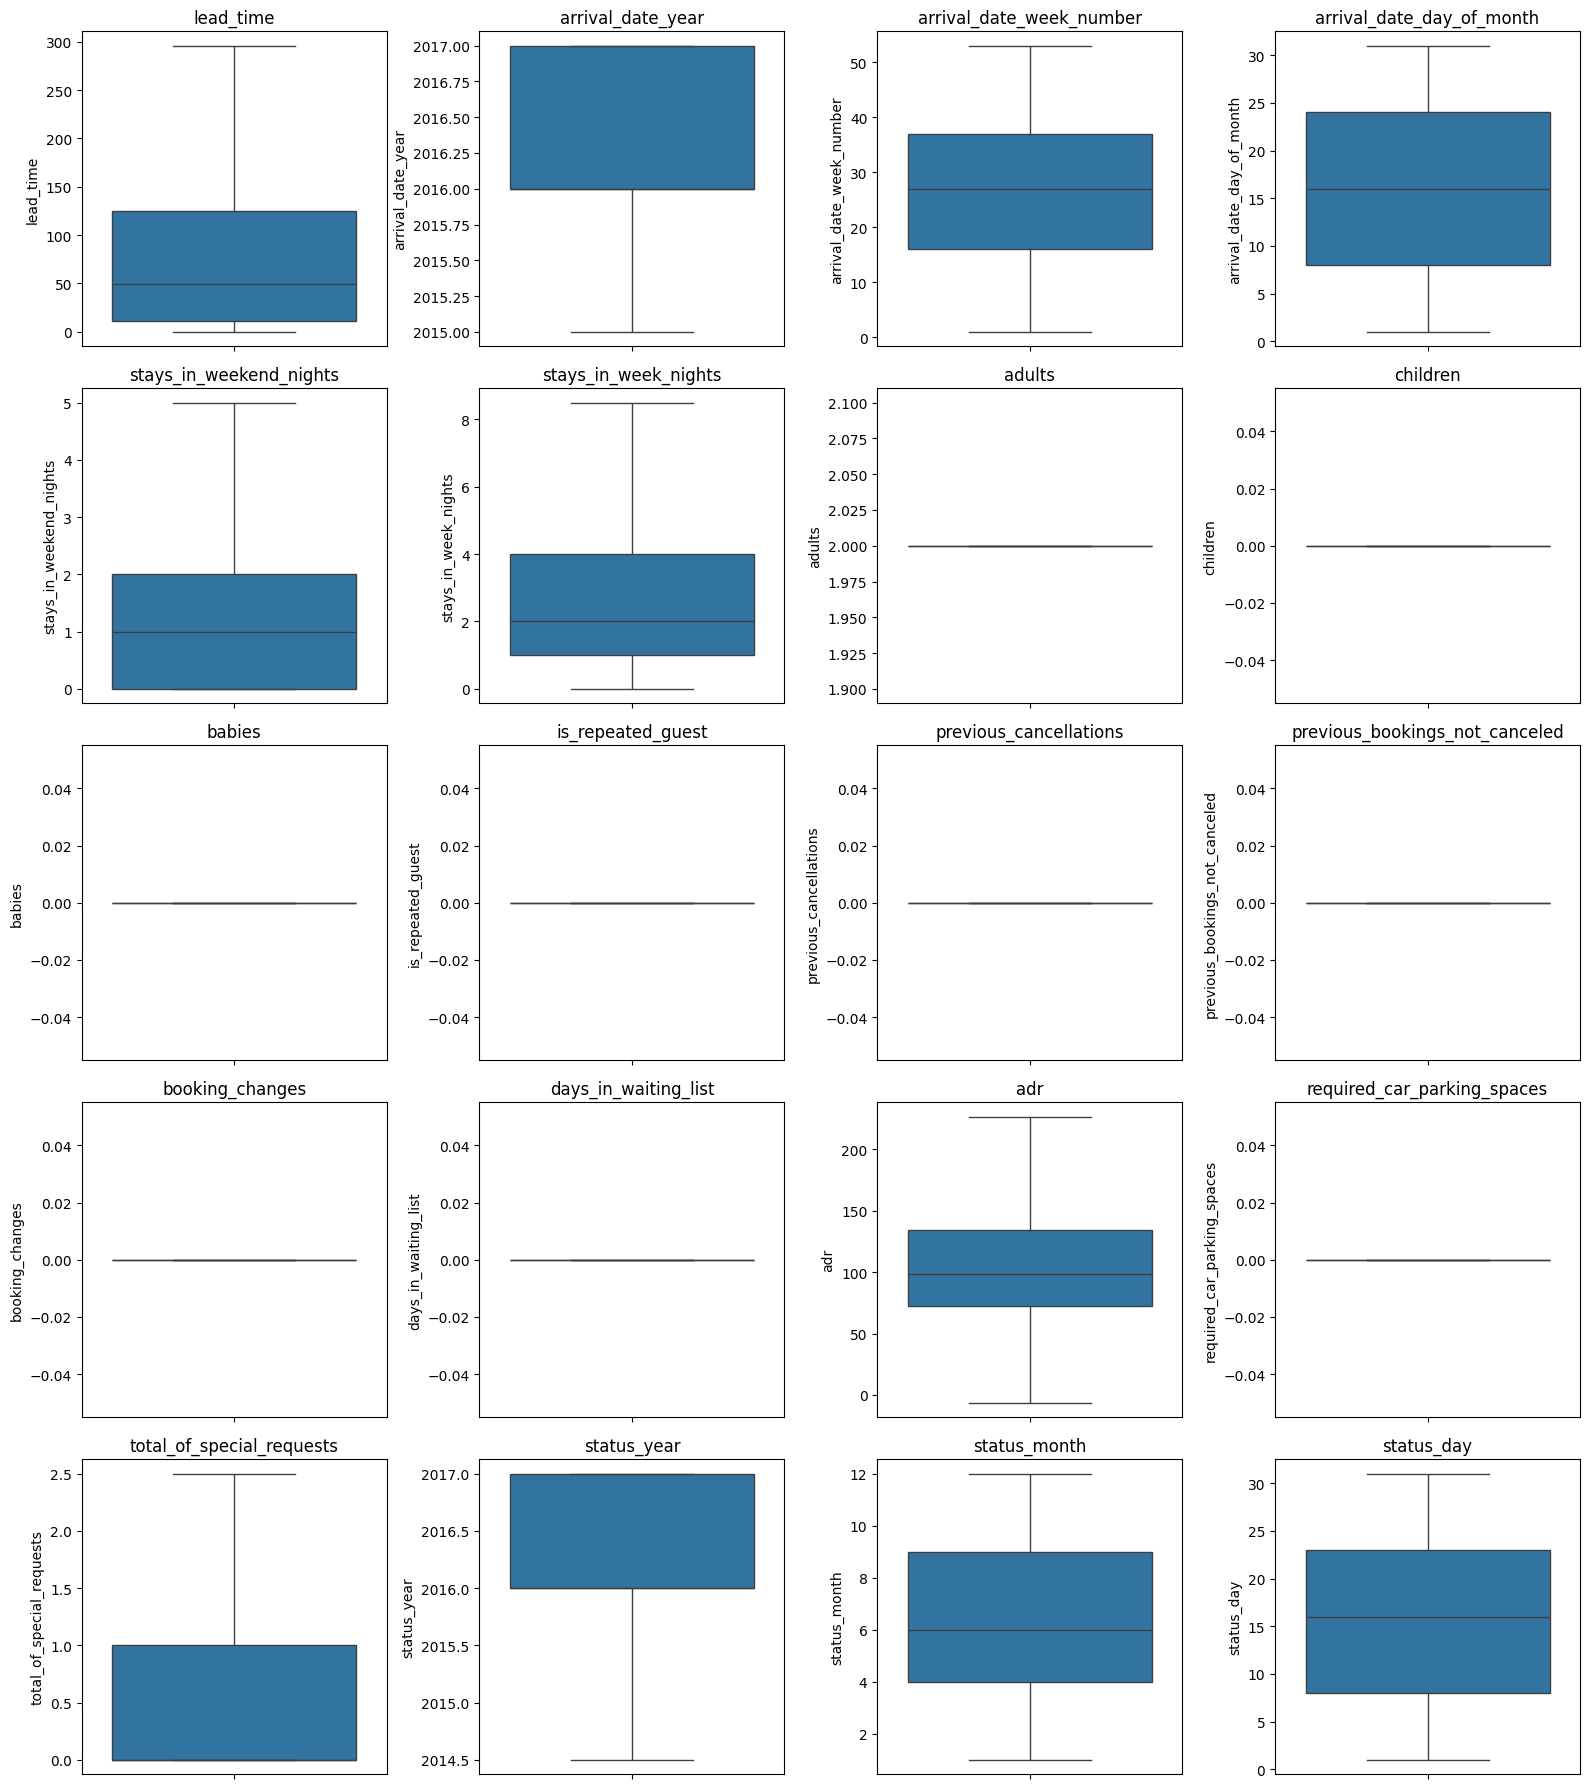

In [ ]:
# checking for outliers after clipping

plt.figure(figsize=(16, 18))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(5, 4, i)
    sns.boxplot(X_train_num_imp[col])
    plt.title(col)
plt.tight_layout()
plt.show()

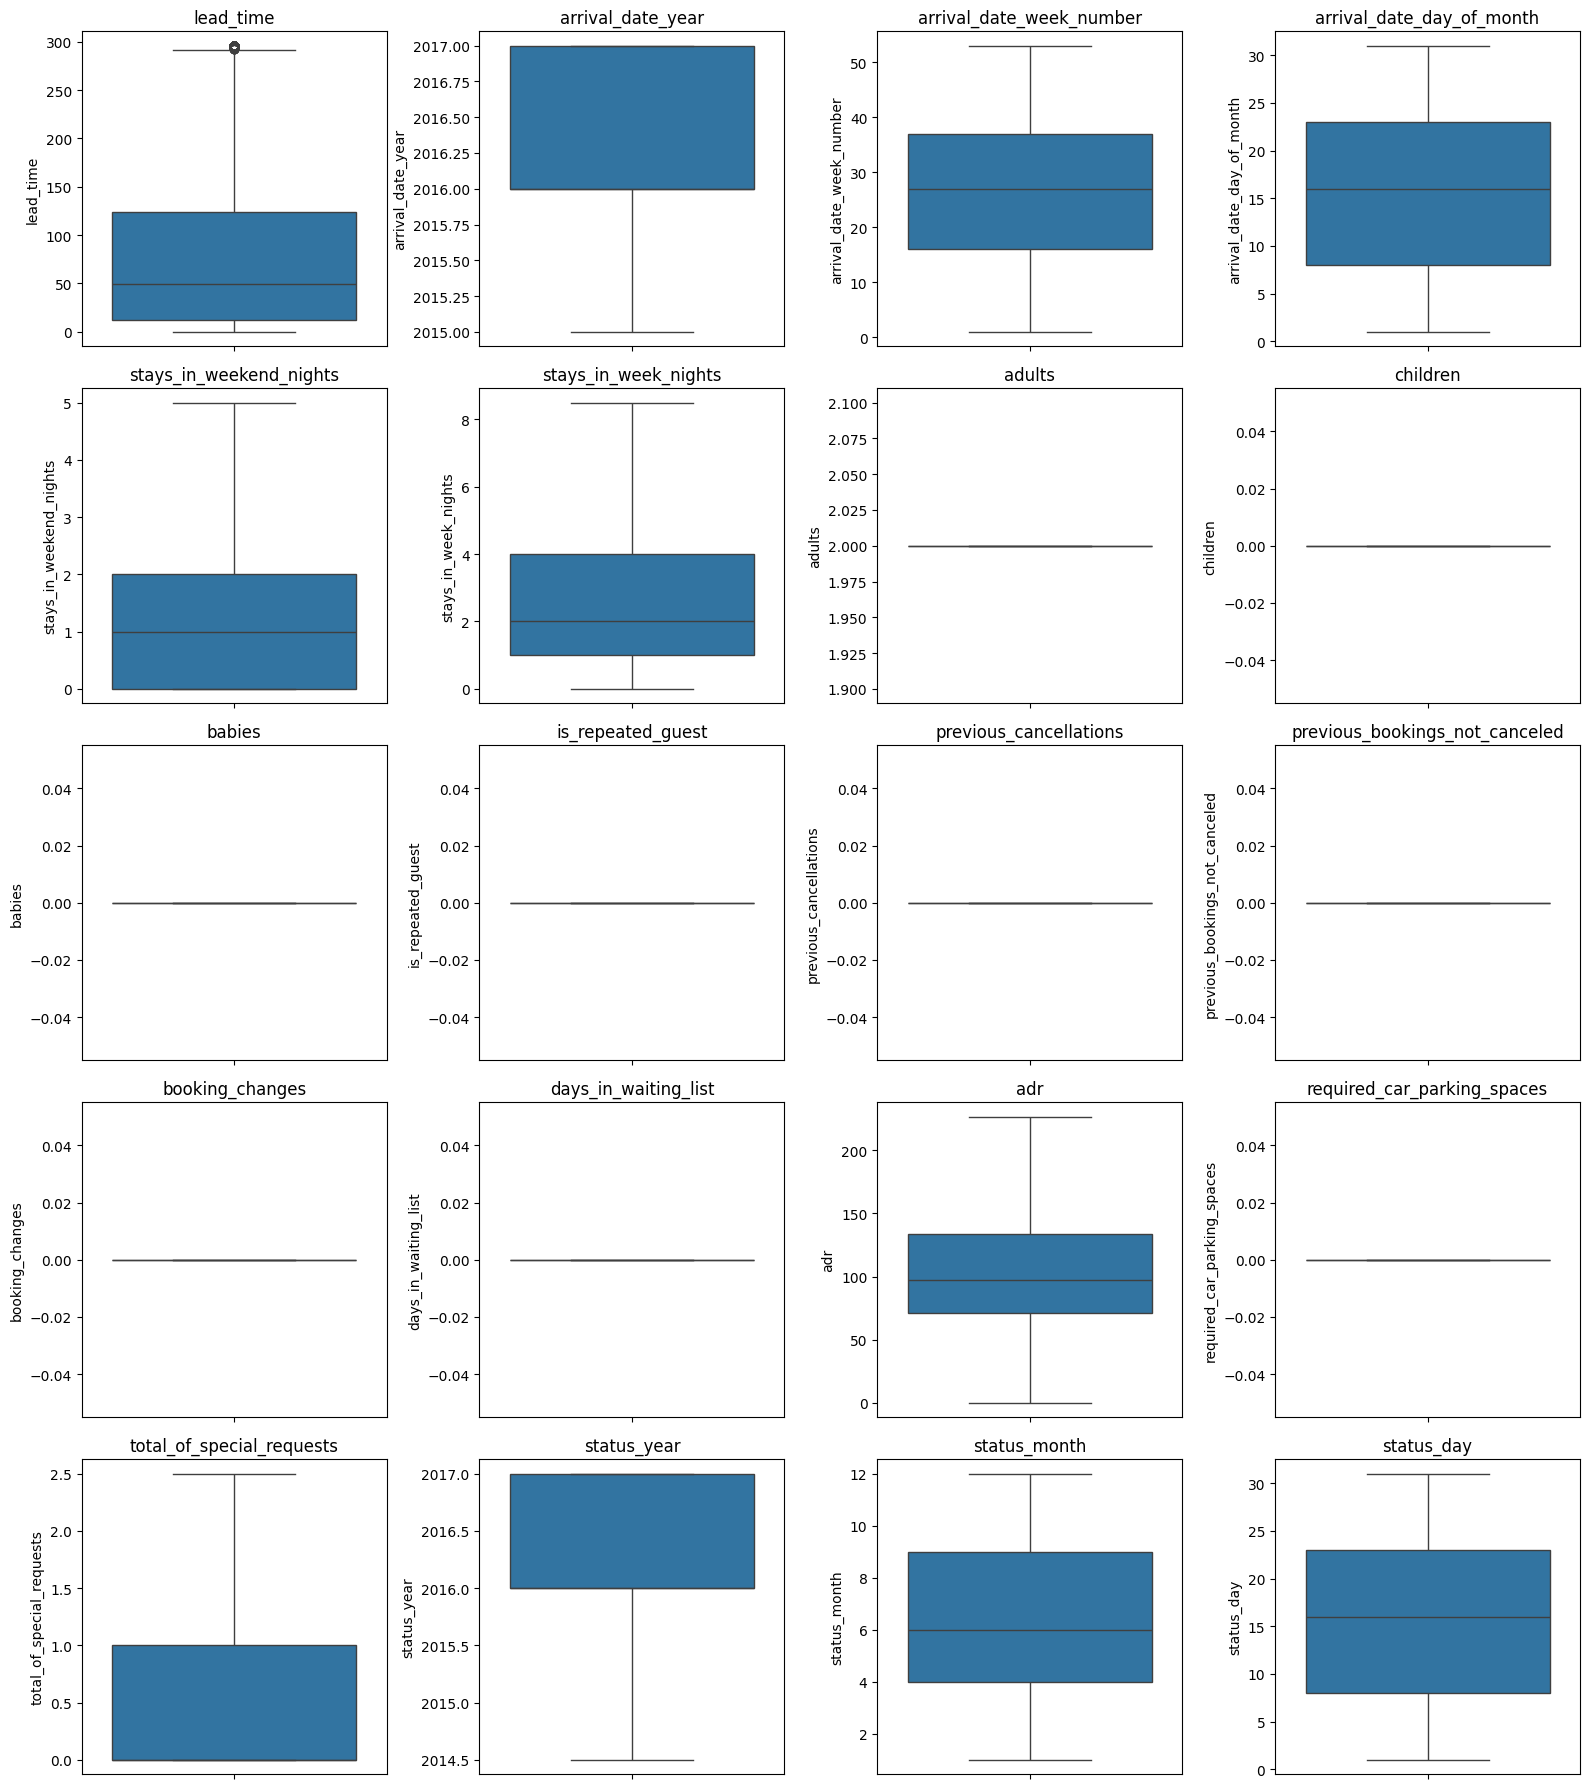

In [ ]:
plt.figure(figsize=(16, 18))
for i, col in enumerate(numerical_cols, 1):
    plt.subplot(5, 4, i)
    sns.boxplot(X_test_num_imp[col])
    plt.title(col)
plt.tight_layout()
plt.show()

# SCALING AND STANDARDIZATION

In [ ]:
# The scaler learns from TRAIN only and applies them to both train and test.
scaler = StandardScaler()

X_train_num_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_num_imp),
    columns=numerical_cols, index=X_train_num_imp.index
)
X_test_num_scaled = pd.DataFrame(
    scaler.transform(X_test_num_imp),
    columns=numerical_cols, index=X_test_num_imp.index
)

print(X_train_num_scaled.head())

# Next steps use: X_train_num_scaled, X_test_num_scaled  (numerical)
#                 X_train_cat, X_test_cat                (categorical)
#                 y_train, y_test                        (target)

        lead_time  arrival_date_year  arrival_date_week_number  \
77305   -0.916601          -1.764413                  0.815336   
114516   0.229715           1.151825                 -0.134628   
103149  -0.694734          -0.306294                  1.692227   
22519   -0.916601          -0.306294                 -1.011518   
514     -0.423562          -1.764413                  0.157669   

        arrival_date_day_of_month  stays_in_weekend_nights  \
77305                   -0.095726                -1.004685   
114516                   0.243809                 1.006814   
103149                  -0.887973                 1.006814   
22519                    1.036057                 0.001065   
514                      0.243809                 1.006814   

        stays_in_week_nights  adults  children  babies  is_repeated_guest  \
77305              -0.319119     0.0       0.0     0.0                0.0   
114516              0.234267     0.0       0.0     0.0                0.0   

In [ ]:
X_train_cat.columns

Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'assigned_room_type',
       'deposit_type', 'customer_type', 'reservation_status'],
      dtype='object')

In [ ]:
for col in X_train_cat:
  print(col)
  print("Unique values",X_train_cat[col].unique())

hotel
Unique values ['City Hotel' 'Resort Hotel']
arrival_date_month
Unique values ['September' 'June' 'December' 'March' 'July' 'April' 'October' 'August'
 'November' 'February' 'January' 'May']
meal
Unique values ['BB' 'SC' 'Undefined' 'FB' 'HB']
country
Unique values ['PRT' 'GBR' 'ITA' 'DEU' 'ESP' 'USA' 'CHE' 'CN' 'JPN' 'FRA' 'IRL' 'BGR'
 'CYP' 'NLD' 'ARG' 'GRC' 'CHN' 'LUX' 'BEL' 'AUT' 'RUS' 'SGP' 'Unknown'
 'IDN' 'ROU' 'UKR' 'POL' 'CZE' 'KAZ' 'BRA' 'DNK' 'HUN' 'MYT' 'DZA' 'AGO'
 'SWE' 'AUS' 'NOR' 'HRV' 'PHL' 'MEX' 'FIN' 'IRN' 'LTU' 'GEO' 'QAT' 'SVK'
 'IND' 'MDV' 'MAR' 'MLT' 'ARE' 'KOR' 'ALB' 'EST' 'CIV' 'ZAF' 'THA' 'COL'
 'ISR' 'TUR' 'SVN' 'SRB' 'BLR' 'NZL' 'CUB' 'SAU' 'NCL' 'ECU' 'LVA' 'CMR'
 'BHR' 'NGA' 'PRI' 'MYS' 'HKG' 'DOM' 'PAN' 'TUN' 'LBN' 'BIH' 'TWN' 'VNM'
 'BGD' 'MOZ' 'CHL' 'GHA' 'URY' 'GAB' 'LCA' 'PAK' 'EGY' 'OMN' 'MKD' 'ARM'
 'VEN' 'CRI' 'FRO' 'PER' 'CYM' 'LBY' 'SEN' 'LKA' 'AZE' 'LIE' 'SUR' 'JEY'
 'RWA' 'CPV' 'JOR' 'GNB' 'ATF' 'KWT' 'TZA' 'AND' 'JAM' 'MUS' 'ATA' 'UZB'
 '

#SECTION 4 - ARYA R.B

#ENCODING

In [ ]:
X_train_cat.columns

Index(['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment',
       'distribution_channel', 'reserved_room_type', 'assigned_room_type',
       'deposit_type', 'customer_type', 'reservation_status'],
      dtype='object')

#ONE HOT ENCODING

In [ ]:
encoder_hot=OneHotEncoder(handle_unknown="ignore",sparse_output=False,dtype=int)
X_train_onehot_df=pd.DataFrame(
    encoder_hot.fit_transform(X_train_cat),
    columns=encoder_hot.get_feature_names_out(),
    index=X_train_cat.index)

X_test_onehot_df = pd.DataFrame(
    encoder_hot.transform(X_test_cat),
    columns=encoder_hot.get_feature_names_out(),
    index=X_test_cat.index
)

In [ ]:
X_train_onehot_df.head()

,hotel_City Hotel,hotel_Resort Hotel,arrival_date_month_April,arrival_date_month_August,arrival_date_month_December,arrival_date_month_February,arrival_date_month_January,arrival_date_month_July,arrival_date_month_June,arrival_date_month_March,arrival_date_month_May,arrival_date_month_November,arrival_date_month_October,arrival_date_month_September,meal_BB,meal_FB,meal_HB,meal_SC,meal_Undefined,country_ABW,country_AGO,country_ALB,country_AND,country_ARE,country_ARG,country_ARM,country_ATA,country_ATF,country_AUS,country_AUT,country_AZE,country_BDI,country_BEL,country_BEN,country_BFA,country_BGD,country_BGR,country_BHR,country_BHS,country_BIH,country_BLR,country_BOL,country_BRA,country_BRB,country_BWA,country_CAF,country_CHE,country_CHL,country_CHN,country_CIV,country_CMR,country_CN,country_COL,country_COM,country_CPV,country_CRI,country_CUB,country_CYM,country_CYP,country_CZE,country_DEU,country_DJI,country_DMA,country_DNK,country_DOM,country_DZA,country_ECU,country_EGY,country_ESP,country_EST,country_ETH,country_FIN,country_FJI,country_FRA,country_FRO,country_GAB,country_GBR,country_GEO,country_GGY,country_GHA,country_GIB,country_GLP,country_GNB,country_GRC,country_GTM,country_GUY,country_HKG,country_HND,country_HRV,country_HUN,country_IDN,country_IMN,country_IND,country_IRL,country_IRN,country_IRQ,country_ISL,country_ISR,country_ITA,country_JAM,country_JEY,country_JOR,country_JPN,country_KAZ,country_KEN,country_KHM,country_KIR,country_KNA,country_KOR,country_KWT,country_LAO,country_LBN,country_LBY,country_LCA,country_LIE,country_LKA,country_LTU,country_LUX,country_LVA,country_MAC,country_MAR,country_MCO,country_MDG,country_MDV,country_MEX,country_MKD,country_MLT,country_MMR,country_MNE,country_MOZ,country_MUS,country_MWI,country_MYS,country_MYT,country_NAM,country_NCL,country_NGA,country_NIC,country_NLD,country_NOR,country_NPL,country_NZL,country_OMN,country_PAK,country_PAN,country_PER,country_PHL,country_PLW,country_POL,country_PRI,country_PRT,country_PRY,country_PYF,country_QAT,country_ROU,country_RUS,country_RWA,country_SAU,country_SDN,country_SEN,country_SGP,country_SLV,country_SMR,country_SRB,country_STP,country_SUR,country_SVK,country_SVN,country_SWE,country_SYC,country_SYR,country_TGO,country_THA,country_TJK,country_TMP,country_TUN,country_TUR,country_TWN,country_TZA,country_UGA,country_UKR,country_UMI,country_URY,country_USA,country_UZB,country_Unknown,country_VEN,country_VGB,country_VNM,country_ZAF,country_ZMB,country_ZWE,market_segment_Aviation,market_segment_Complementary,market_segment_Corporate,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,distribution_channel_Corporate,distribution_channel_Direct,distribution_channel_GDS,distribution_channel_TA/TO,reserved_room_type_A,reserved_room_type_B,reserved_room_type_C,reserved_room_type_D,reserved_room_type_E,reserved_room_type_F,reserved_room_type_G,reserved_room_type_H,reserved_room_type_L,reserved_room_type_P,assigned_room_type_A,assigned_room_type_B,assigned_room_type_C,assigned_room_type_D,assigned_room_type_E,assigned_room_type_F,assigned_room_type_G,assigned_room_type_H,assigned_room_type_I,assigned_room_type_K,assigned_room_type_P,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,reservation_status_Canceled,reservation_status_Check-Out,reservation_status_No-Show
77305,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0
114516,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0

In [ ]:
#Concating numerical and categorical columns
X_train_final = pd.concat([X_train_onehot_df,X_train_num_scaled],axis=1)
X_test_final = pd.concat([X_test_onehot_df,X_test_num_scaled],axis=1)

In [ ]:
X_train_final.head()

,hotel_City Hotel,hotel_Resort Hotel,arrival_date_month_April,arrival_date_month_August,arrival_date_month_December,arrival_date_month_February,arrival_date_month_January,arrival_date_month_July,arrival_date_month_June,arrival_date_month_March,arrival_date_month_May,arrival_date_month_November,arrival_date_month_October,arrival_date_month_September,meal_BB,meal_FB,meal_HB,meal_SC,meal_Undefined,country_ABW,country_AGO,country_ALB,country_AND,country_ARE,country_ARG,country_ARM,country_ATA,country_ATF,country_AUS,country_AUT,country_AZE,country_BDI,country_BEL,country_BEN,country_BFA,country_BGD,country_BGR,country_BHR,country_BHS,country_BIH,country_BLR,country_BOL,country_BRA,country_BRB,country_BWA,country_CAF,country_CHE,country_CHL,country_CHN,country_CIV,country_CMR,country_CN,country_COL,country_COM,country_CPV,country_CRI,country_CUB,country_CYM,country_CYP,country_CZE,country_DEU,country_DJI,country_DMA,country_DNK,country_DOM,country_DZA,country_ECU,country_EGY,country_ESP,country_EST,country_ETH,country_FIN,country_FJI,country_FRA,country_FRO,country_GAB,country_GBR,country_GEO,country_GGY,country_GHA,country_GIB,country_GLP,country_GNB,country_GRC,country_GTM,country_GUY,country_HKG,country_HND,country_HRV,country_HUN,country_IDN,country_IMN,country_IND,country_IRL,country_IRN,country_IRQ,country_ISL,country_ISR,country_ITA,country_JAM,country_JEY,country_JOR,country_JPN,country_KAZ,country_KEN,country_KHM,country_KIR,country_KNA,country_KOR,country_KWT,country_LAO,country_LBN,country_LBY,country_LCA,country_LIE,country_LKA,country_LTU,country_LUX,country_LVA,country_MAC,country_MAR,country_MCO,country_MDG,country_MDV,country_MEX,country_MKD,country_MLT,country_MMR,country_MNE,country_MOZ,country_MUS,country_MWI,country_MYS,country_MYT,country_NAM,country_NCL,country_NGA,country_NIC,country_NLD,country_NOR,country_NPL,country_NZL,country_OMN,country_PAK,country_PAN,country_PER,country_PHL,country_PLW,country_POL,country_PRI,country_PRT,country_PRY,country_PYF,country_QAT,country_ROU,country_RUS,country_RWA,country_SAU,country_SDN,country_SEN,country_SGP,country_SLV,country_SMR,country_SRB,country_STP,country_SUR,country_SVK,country_SVN,country_SWE,country_SYC,country_SYR,country_TGO,country_THA,country_TJK,country_TMP,country_TUN,country_TUR,country_TWN,country_TZA,country_UGA,country_UKR,country_UMI,country_URY,country_USA,country_UZB,country_Unknown,country_VEN,country_VGB,country_VNM,country_ZAF,country_ZMB,country_ZWE,market_segment_Aviation,market_segment_Complementary,market_segment_Corporate,market_segment_Direct,market_segment_Groups,market_segment_Offline TA/TO,market_segment_Online TA,distribution_channel_Corporate,distribution_channel_Direct,distribution_channel_GDS,distribution_channel_TA/TO,reserved_room_type_A,reserved_room_type_B,reserved_room_type_C,reserved_room_type_D,reserved_room_type_E,reserved_room_type_F,reserved_room_type_G,reserved_room_type_H,reserved_room_type_L,reserved_room_type_P,assigned_room_type_A,assigned_room_type_B,assigned_room_type_C,assigned_room_type_D,assigned_room_type_E,assigned_room_type_F,assigned_room_type_G,assigned_room_type_H,assigned_room_type_I,assigned_room_type_K,assigned_room_type_P,deposit_type_No Deposit,deposit_type_Non Refund,deposit_type_Refundable,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party,reservation_status_Canceled,reservation_status_Check-Out,reservation_status_No-Show,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,status_year,status_month,status_day
77305,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,

In [ ]:
X_train_final.columns

Index(['hotel_City Hotel', 'hotel_Resort Hotel', 'arrival_date_month_April',
       'arrival_date_month_August', 'arrival_date_month_December',
       'arrival_date_month_February', 'arrival_date_month_January',
       'arrival_date_month_July', 'arrival_date_month_June',
       'arrival_date_month_March',
       ...
       'previous_cancellations', 'previous_bookings_not_canceled',
       'booking_changes', 'days_in_waiting_list', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'status_year', 'status_month', 'status_day'],
      dtype='object', length=254)

#LABEL ENCODING FOR TARGET

In [ ]:
y_train.unique()

array([0, 1])

In [ ]:
encoder_lb=LabelEncoder()
y_train_enc=encoder_lb.fit_transform(y_train)
y_test_enc=encoder_lb.transform(y_test)
print(encoder_lb.classes_)
print(pd.Series(y_train_enc).value_counts())

[0 1]
0    50696
1    19217
Name: count, dtype: int64
